# Elektrik Tüketiminde Anomali Analizi

**Amaç:** Tek bir haneye ait dakika bazlı elektrik tüketiminde sıra dışı günleri ve uzun süreli düşük tüketim dönemlerini belirlemek; farklı yöntemlerin ürettiği inceleme adaylarını karşılaştırmak.

**Veri:** UCI *Individual Household Electric Power Consumption*, Aralık 2006–Kasım 2010. Bu çalışma tek bir haneye ait, doğrulanmış anomali etiketi içermeyen geçmiş veriler üzerinde keşifsel analizdir. Düşük tüketim, tek başına usulsüz kullanım veya arıza kanıtı değildir.

**Çalıştırma:** Notebook `notebooks/` klasöründe, ham veri `data/household_power_consumption.txt` konumundayken hücreleri yukarıdan aşağıya çalıştırın. Analiz sonuçları ve grafikler `outputs/` klasörüne kaydedilir.

In [1]:
from pathlib import Path

Path("../outputs/figures").mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Veri boyutu:", df.shape)
display(df.head())


Veri boyutu: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 1. Veri yapısı ve kalite kontrolü
Önce ham verinin sütunlarını, eksik değerlerini ve tarih aralığını inceleyelim.

In [2]:

print(df.info())

print("\nEksik değerler:")
print(df.isnull().sum())

print("\nTemel istatistikler:")
display(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB
None

Eksik değerler:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Temel istatistikler:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [3]:
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df = df.sort_values("datetime").reset_index(drop=True)

print("İlk tarih:", df["datetime"].min())
print("Son tarih:", df["datetime"].max())
print("Geçersiz tarih:", df["datetime"].isna().sum())
print("Tekrarlanan zaman:", df["datetime"].duplicated().sum())

İlk tarih: 2006-12-16 17:24:00
Son tarih: 2010-11-26 21:02:00
Geçersiz tarih: 0
Tekrarlanan zaman: 0


In [4]:

measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Bütün ölçümleri eksik olan satırlar
all_missing = df[measurement_cols].isna().all(axis=1)

# En az bir ölçümü eksik olan satırlar
any_missing = df[measurement_cols].isna().any(axis=1)

print("Tamamen eksik satır:", all_missing.sum())

print(
    "Kısmen eksik satır:",
    (any_missing & ~all_missing).sum()
)

# Eksik ölçümlerin günlere dağılımı
missing_by_day = (
    df.loc[any_missing]
    .groupby(df["datetime"].dt.date)
    .size()
    .sort_values(ascending=False)
)

print("\nEn fazla eksik ölçüm olan 10 gün:")
print(missing_by_day.head(10))


Tamamen eksik satır: 25979
Kısmen eksik satır: 0

En fazla eksik ölçüm olan 10 gün:
datetime
2010-08-20    1440
2009-06-14    1440
2010-09-27    1440
2010-09-26    1440
2010-08-18    1440
2007-04-29    1440
2010-01-13    1440
2010-08-19    1440
2010-08-21    1440
2007-04-28    1419
dtype: int64


In [5]:

# Eksik satırların başlangıçlarını belirle
gap_start = (
    all_missing
    & (
        ~all_missing.shift(fill_value=False)
        | df["datetime"].diff().ne(pd.Timedelta(minutes=1))
    )
)

# Her eksik ölçüm grubuna numara ver
gap_id = gap_start.cumsum()

# Kesintileri özetle
missing_periods = (
    df.loc[all_missing]
    .groupby(gap_id[all_missing])
    .agg(
        start=("datetime", "min"),
        end=("datetime", "max"),
        missing_minutes=("datetime", "size")
    )
)

# En uzun kesintiler
missing_periods = missing_periods.sort_values(
    "missing_minutes",
    ascending=False
)

display(missing_periods.head(10))


,start,end,missing_minutes
69,2010-08-17 21:02:00,2010-08-22 21:27:00,7226
70,2010-09-25 03:56:00,2010-09-28 19:12:00,5237
7,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
50,2009-06-13 00:30:00,2009-06-15 07:34:00,3305
59,2010-01-12 14:53:00,2010-01-14 19:01:00,3129
63,2010-03-20 03:52:00,2010-03-21 13:38:00,2027
52,2009-08-13 05:00:00,2009-08-13 19:50:00,891
16,2007-07-15 16:49:00,2007-07-15 18:11:00,83
39,2008-12-10 10:48:00,2008-12-10 11:57:00,70
17,2007-07-15 18:21:00,2007-07-15 19:07:00,47


## 2. Eksik kayıtlar ve temizleme
Bütün ölçümleri eksik olan satırları ve kesintisiz eksik kayıt aralıklarını belirliyoruz. Kaydedilen eksik dönemler, sonraki analizlerin yorumlanmasında veri kalitesi göstergesidir.

In [6]:

# Eksik ölçüm aralıklarını kaydet
missing_periods.to_csv(
    "../outputs/missing_periods.csv",
    index=False
)

# Orijinal veriyi değiştirmeden temiz bir kopya oluştur
df_clean = df.loc[~any_missing].copy()

# Artık ihtiyaç duymadığımız tarih sütunlarını kaldır
df_clean = df_clean.drop(
    columns=["Date", "Time"]
)

# Tarihe göre sırala
df_clean = df_clean.sort_values("datetime")
df_clean = df_clean.reset_index(drop=True)

# Temizlenmiş veriyi kaydet
df_clean.to_csv(
    "../data/cleaned_consumption.csv",
    index=False
)

print("Orijinal kayıt:", len(df))
print("Temiz kayıt:", len(df_clean))
print("Çıkarılan kayıt:", len(df) - len(df_clean))
print("Kalan eksik değer:", df_clean.isna().sum().sum())


Orijinal kayıt: 2075259
Temiz kayıt: 2049280
Çıkarılan kayıt: 25979
Kalan eksik değer: 0


## 3. Günlük enerji hesabı
Dakika bazında örneklenen aktif güç (kW) değerlerinin toplamını 60’a bölerek günlük enerjiyi yaklaşık kWh cinsinden hesaplıyoruz. En az 1.380 ölçümü olmayan günleri dışlıyoruz; eksik dakikaları tamamlamıyoruz. Bu nedenle kısmen eksik günlerin enerji toplamları düşük hesaplanabilir.

In [7]:

# Günlük tüketim ve ölçüm sayısı
daily = (
    df_clean.set_index("datetime")
    .resample("D")
    .agg(
        total_power=("Global_active_power", "sum"),
        measurement_count=("Global_active_power", "count")
    )
)

# Günlük toplam enerji (kWh)
daily["energy_kwh"] = daily["total_power"] / 60

# Yeterli ölçüm bulunmayan günleri işaretle
daily["valid_day"] = daily["measurement_count"] >= 1380

# Eksik günleri grafikte göstermemek için
daily.loc[~daily["valid_day"], "energy_kwh"] = np.nan

print(daily.head(10))
print("\nYeterli ölçüm bulunan gün:",
      daily["valid_day"].sum())

print("Yetersiz ölçüm bulunan gün:",
      (~daily["valid_day"]).sum())


            total_power  measurement_count  energy_kwh  valid_day
datetime                                                         
2006-12-16     1209.176                396         NaN      False
2006-12-17     3390.460               1440   56.507667       True
2006-12-18     2203.826               1440   36.730433       True
2006-12-19     1666.194               1440   27.769900       True
2006-12-20     2225.748               1440   37.095800       True
2006-12-21     1716.624               1438   28.610400       True
2006-12-22     2341.338               1440   39.022300       True
2006-12-23     4773.386               1440   79.556433       True
2006-12-24     2550.012               1440   42.500200       True
2006-12-25     2743.120               1440   45.718667       True

Yeterli ölçüm bulunan gün: 1416
Yetersiz ölçüm bulunan gün: 26


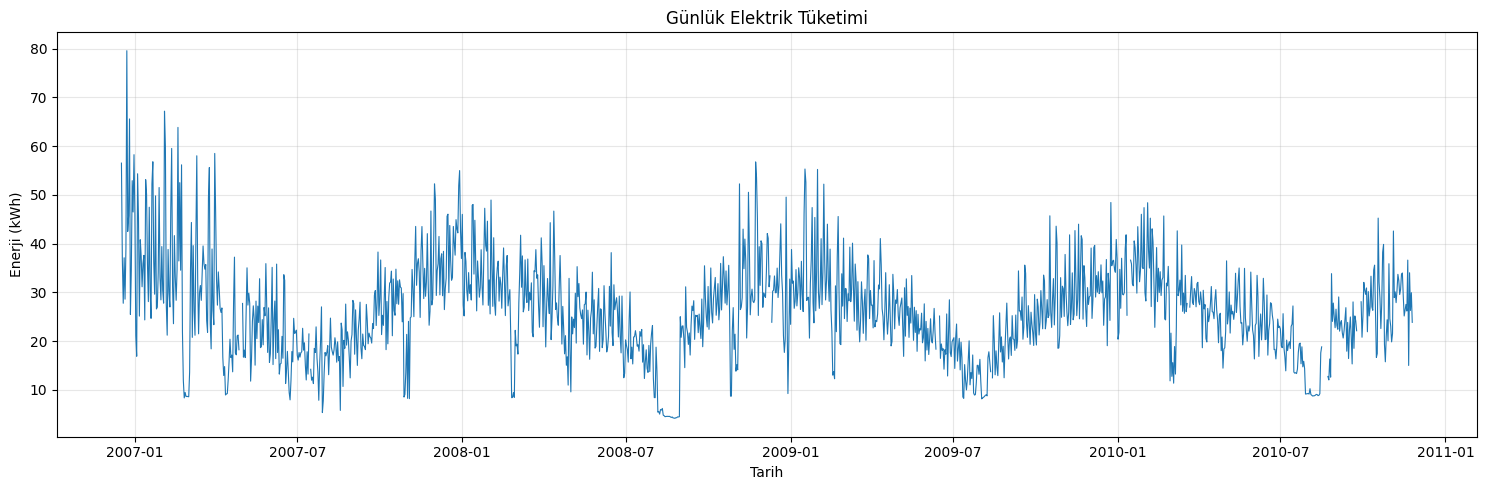

In [8]:

plt.figure(figsize=(15, 5))

plt.plot(
    daily.index,
    daily["energy_kwh"],
    linewidth=0.8
)

plt.title("Günlük Elektrik Tüketimi")
plt.xlabel("Tarih")
plt.ylabel("Enerji (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/daily_consumption.png",
    dpi=150
)

plt.show()


## 4. Keşifsel veri analizi
Saatlik kullanım, hafta içi/hafta sonu davranışı, aylık ve mevsimsel dağılımlar incelenir.

,mean,median,count
datetime,,,
0,0.659434,0.366,85491
1,0.539325,0.328,85440
2,0.480621,0.320,85439
3,0.444866,0.314,85428
4,0.443847,0.312,85317
5,0.453674,0.310,85260
6,0.791600,0.350,85259
7,1.502246,1.502,85284
8,1.461016,1.410,85295


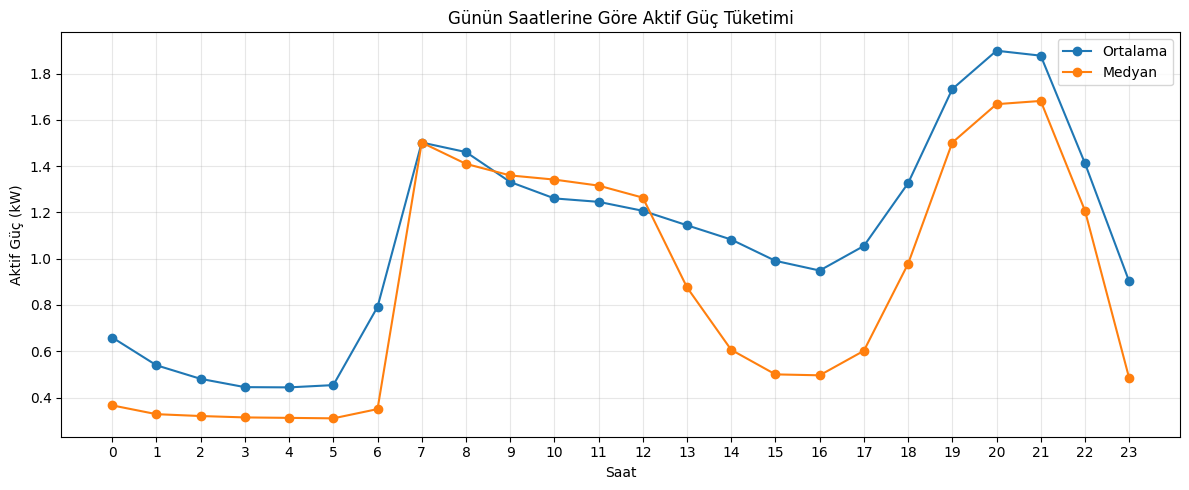

In [9]:

# Saatlik ortalama ve medyan güç tüketimi
hourly = (
    df_clean
    .groupby(df_clean["datetime"].dt.hour)["Global_active_power"]
    .agg(["mean", "median", "count"])
)

display(hourly)

# Saatlik tüketim grafiği
plt.figure(figsize=(12, 5))

plt.plot(
    hourly.index,
    hourly["mean"],
    marker="o",
    label="Ortalama"
)

plt.plot(
    hourly.index,
    hourly["median"],
    marker="o",
    label="Medyan"
)

plt.title("Günün Saatlerine Göre Aktif Güç Tüketimi")
plt.xlabel("Saat")
plt.ylabel("Aktif Güç (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/hourly_consumption.png",
    dpi=150
)

plt.show()


day_type,Hafta içi,Hafta sonu
hour,,
0,0.568563,0.889171
1,0.467771,0.720608
2,0.435256,0.595550
3,0.411625,0.529124
4,0.425725,0.489988
5,0.430645,0.512250
6,0.875243,0.578843
7,1.715033,0.960751
8,1.579932,1.158365


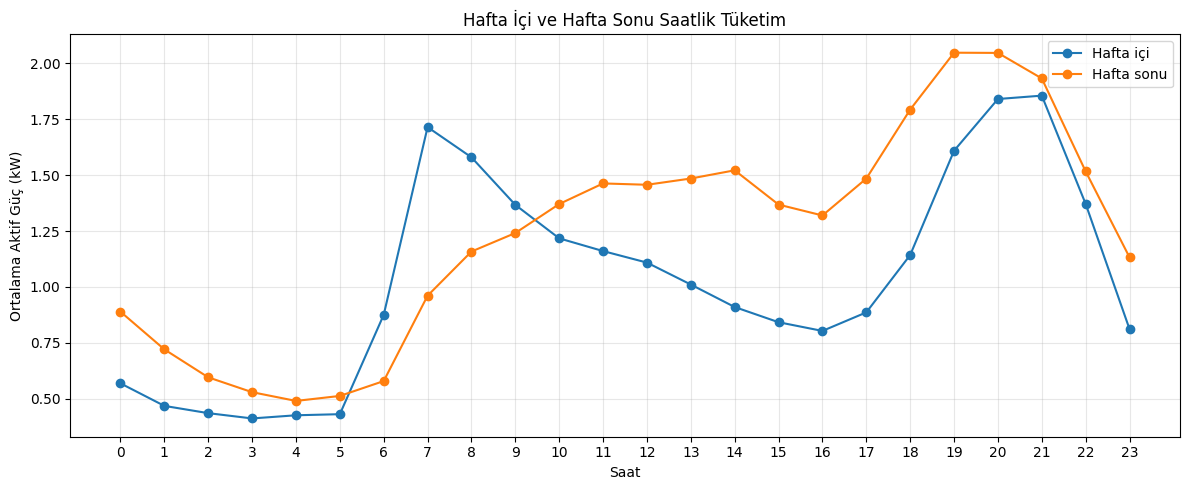

In [10]:

# Haftanın günü: Pazartesi=0, Pazar=6
df_clean["day_of_week"] = df_clean["datetime"].dt.dayofweek

# Hafta içi / hafta sonu ayrımı
df_clean["day_type"] = np.where(
    df_clean["day_of_week"] < 5,
    "Hafta içi",
    "Hafta sonu"
)

# Saat bilgisini ayrı bir sütuna al
df_clean["hour"] = df_clean["datetime"].dt.hour

# Gün türüne ve saate göre ortalama güç
weekday_hourly = (
    df_clean.groupby(["day_type", "hour"])["Global_active_power"]
    .mean()
    .unstack(0)
)

display(weekday_hourly)

plt.figure(figsize=(12, 5))

plt.plot(
    weekday_hourly.index,
    weekday_hourly["Hafta içi"],
    marker="o",
    label="Hafta içi"
)

plt.plot(
    weekday_hourly.index,
    weekday_hourly["Hafta sonu"],
    marker="o",
    label="Hafta sonu"
)

plt.title("Hafta İçi ve Hafta Sonu Saatlik Tüketim")
plt.xlabel("Saat")
plt.ylabel("Ortalama Aktif Güç (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/weekday_vs_weekend.png",
    dpi=150
)

plt.show()


## 5. İstatistiksel uç değer analizi
Önce tüm günlere uygulanan IQR, ardından takvim ayına göre hesaplanan IQR ile mevsimselliğin etkisini karşılaştırıyoruz. Bunlar doğrulanmış anomali etiketleri değil, istatistiksel inceleme adaylarıdır.

count    1416.000000
mean       26.187206
std        10.000942
min         4.171633
25%        19.658267
50%        25.917400
75%        31.656917
max        79.556433
Name: energy_kwh, dtype: float64

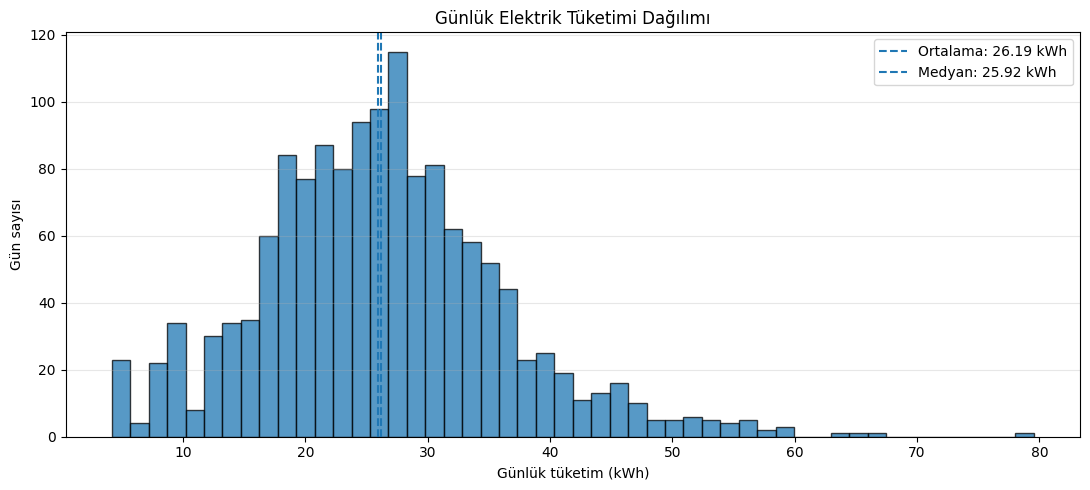

In [11]:

# Yalnızca yeterli ölçüme sahip günler
valid_daily = daily.loc[
    daily["valid_day"], "energy_kwh"
]

# Günlük tüketim istatistikleri
display(valid_daily.describe())

# Histogram
plt.figure(figsize=(11, 5))

plt.hist(
    valid_daily,
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    valid_daily.mean(),
    linestyle="--",
    label=f"Ortalama: {valid_daily.mean():.2f} kWh"
)

plt.axvline(
    valid_daily.median(),
    linestyle="--",
    label=f"Medyan: {valid_daily.median():.2f} kWh"
)

plt.title("Günlük Elektrik Tüketimi Dağılımı")
plt.xlabel("Günlük tüketim (kWh)")
plt.ylabel("Gün sayısı")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/daily_distribution.png",
    dpi=150
)

plt.show()


In [12]:

# Çeyrekleri hesapla
q1 = valid_daily.quantile(0.25)
q3 = valid_daily.quantile(0.75)

# Çeyrekler arası açıklık
iqr = q3 - q1

# IQR sınırları
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Sınırların dışındaki günler
outlier_days = valid_daily[
    (valid_daily < lower_bound) |
    (valid_daily > upper_bound)
]

print(f"Q1: {q1:.2f} kWh")
print(f"Q3: {q3:.2f} kWh")
print(f"IQR: {iqr:.2f} kWh")
print(f"Alt sınır: {lower_bound:.2f} kWh")
print(f"Üst sınır: {upper_bound:.2f} kWh")
print(f"Aday uç değer sayısı: {len(outlier_days)}")

display(outlier_days.sort_values(ascending=False).head(10))


Q1: 19.66 kWh
Q3: 31.66 kWh
IQR: 12.00 kWh
Alt sınır: 1.66 kWh
Üst sınır: 49.65 kWh
Aday uç değer sayısı: 32


datetime
2006-12-23    79.556433
2007-02-03    67.162033
2006-12-26    65.568500
2007-02-18    63.829367
2007-02-04    59.932333
2007-02-11    59.520467
2007-03-31    58.491833
2006-12-31    58.236600
2007-03-11    58.010600
2007-01-21    56.787700
Name: energy_kwh, dtype: float64

Uç değerlerin aylara göre dağılımı:


,outlier_count
month,
1,10
2,7
3,3
4,0
5,0
6,0
7,0
8,0
9,0


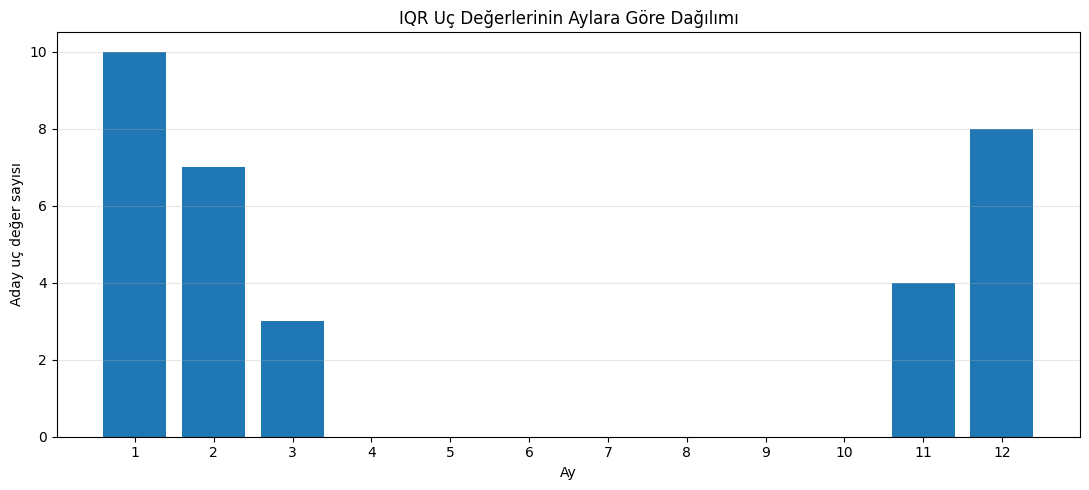

In [13]:

# Aday uç değerleri tarih ve tüketim sütunlarıyla tabloya dönüştür
outlier_df = outlier_days.reset_index()
outlier_df.columns = ["datetime", "energy_kwh"]

# Ay ve yıl bilgilerini ekle
outlier_df["month"] = outlier_df["datetime"].dt.month
outlier_df["year"] = outlier_df["datetime"].dt.year

# Uç değerlerin aylara göre dağılımı
outliers_by_month = (
    outlier_df.groupby("month")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

print("Uç değerlerin aylara göre dağılımı:")
display(outliers_by_month.to_frame("outlier_count"))

# Aylık grafik
plt.figure(figsize=(11, 5))

plt.bar(
    outliers_by_month.index,
    outliers_by_month.values
)

plt.title("IQR Uç Değerlerinin Aylara Göre Dağılımı")
plt.xlabel("Ay")
plt.ylabel("Aday uç değer sayısı")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/outliers_by_month.png",
    dpi=150
)

plt.show()


In [14]:

# Geçerli günleri tabloya dönüştür
monthly_df = valid_daily.reset_index()
monthly_df.columns = ["datetime", "energy_kwh"]

# Ay bilgisini ekle
monthly_df["month"] = monthly_df["datetime"].dt.month

# Her ay için tüketim istatistikleri
monthly_stats = (
    monthly_df.groupby("month")["energy_kwh"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(monthly_stats.round(2))


,count,mean,median,std,min,max
month,,,,,,
1,121,35.07,34.06,8.69,16.90,56.79
2,113,31.20,31.29,11.76,8.36,67.16
3,122,29.55,29.65,8.71,8.59,58.49
4,117,25.16,25.65,7.34,8.96,46.67
5,124,24.71,25.08,5.22,9.60,36.47
6,117,21.83,21.15,5.89,7.96,38.15
7,123,16.81,17.11,4.52,5.35,30.08
8,117,13.67,12.93,7.03,4.17,33.84
9,116,23.41,22.99,4.46,14.57,38.28


In [15]:

# Her ay için birinci ve üçüncü çeyrekleri hesapla
monthly_iqr = (
    monthly_df.groupby("month")["energy_kwh"]
    .agg(
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
)

# Her ayın IQR değerini ve sınırlarını hesapla
monthly_iqr["iqr"] = monthly_iqr["q3"] - monthly_iqr["q1"]

monthly_iqr["lower_bound"] = (
    monthly_iqr["q1"] - 1.5 * monthly_iqr["iqr"]
)

monthly_iqr["upper_bound"] = (
    monthly_iqr["q3"] + 1.5 * monthly_iqr["iqr"]
)

display(monthly_iqr.round(2))


,q1,q3,iqr,lower_bound,upper_bound
month,,,,,
1,28.46,39.20,10.73,12.37,55.29
2,26.43,36.38,9.95,11.51,51.30
3,24.20,33.92,9.72,9.62,48.49
4,19.90,28.48,8.58,7.04,41.34
5,21.49,27.42,5.92,12.61,36.30
6,17.78,25.58,7.79,6.10,37.27
7,13.71,19.73,6.02,4.69,28.75
8,8.43,18.83,10.40,-7.17,34.43
9,20.46,26.00,5.53,12.16,34.30


In [16]:

# Her güne kendi ayının IQR sınırlarını ekle
monthly_df = monthly_df.merge(
    monthly_iqr[["lower_bound", "upper_bound"]],
    left_on="month",
    right_index=True,
    how="left"
)

# Aylık IQR'ye göre aday uç değerler
monthly_df["monthly_outlier"] = (
    (monthly_df["energy_kwh"] < monthly_df["lower_bound"]) |
    (monthly_df["energy_kwh"] > monthly_df["upper_bound"])
)

# Önceden hesapladığımız yıllık IQR ile karşılaştır
monthly_df["yearly_outlier"] = (
    (monthly_df["energy_kwh"] < lower_bound) |
    (monthly_df["energy_kwh"] > upper_bound)
)

print(
    "Yıllık IQR aday sayısı:",
    monthly_df["yearly_outlier"].sum()
)

print(
    "Aylık IQR aday sayısı:",
    monthly_df["monthly_outlier"].sum()
)

print(
    "Yalnızca aylık IQR'nin işaretlediği:",
    (
        monthly_df["monthly_outlier"] &
        ~monthly_df["yearly_outlier"]
    ).sum()
)

print(
    "Yalnızca yıllık IQR'nin işaretlediği:",
    (
        monthly_df["yearly_outlier"] &
        ~monthly_df["monthly_outlier"]
    ).sum()
)

print("\nAylık IQR adaylarının aylara dağılımı:")
display(
    monthly_df.groupby("month")["monthly_outlier"]
    .sum()
    .to_frame("outlier_count")
)


Yıllık IQR aday sayısı: 32
Aylık IQR aday sayısı: 50
Yalnızca aylık IQR'nin işaretlediği: 32
Yalnızca yıllık IQR'nin işaretlediği: 14

Aylık IQR adaylarının aylara dağılımı:


,outlier_count
month,
1,2
2,15
3,6
4,3
5,3
6,1
7,1
8,0
9,4


In [17]:

# Yalnızca aylık IQR'nin işaretlediği günler
monthly_only = monthly_df[
    monthly_df["monthly_outlier"]
    & ~monthly_df["yearly_outlier"]
].copy()

# Alt sınır mı, üst sınır mı aşıldı?
monthly_only["outlier_type"] = np.where(
    monthly_only["energy_kwh"] < monthly_only["lower_bound"],
    "Düşük tüketim",
    "Yüksek tüketim"
)

print("Yalnızca aylık IQR'nin bulduğu gün sayısı:",
      len(monthly_only))

print("\nUç değer türleri:")
print(monthly_only["outlier_type"].value_counts())

print("\nAday günler:")
display(
    monthly_only[
        ["datetime", "energy_kwh", "month",
         "lower_bound", "upper_bound", "outlier_type"]
    ].sort_values("datetime").round(2)
)


Yalnızca aylık IQR'nin bulduğu gün sayısı: 32

Uç değer türleri:
outlier_type
Düşük tüketim     19
Yüksek tüketim    13
Name: count, dtype: int64

Aday günler:


,datetime,energy_kwh,month,lower_bound,upper_bound,outlier_type
70,2007-02-25,8.36,2,11.51,51.30,Düşük tüketim
71,2007-02-26,9.47,2,11.51,51.30,Düşük tüketim
72,2007-02-27,8.64,2,11.51,51.30,Düşük tüketim
73,2007-02-28,8.68,2,11.51,51.30,Düşük tüketim
74,2007-03-01,8.63,3,9.62,48.49,Düşük tüketim
75,2007-03-02,8.59,3,9.62,48.49,Düşük tüketim
97,2007-03-24,49.47,3,9.62,48.49,Yüksek tüketim
105,2007-04-01,46.43,4,7.04,41.34,Yüksek tüketim
141,2007-05-10,11.80,5,12.61,36.30,Düşük tüketim
282,2007-09-29,38.28,9,12.16,34.30,Yüksek tüketim


## 6. Düşük tüketim dönemlerinin ilk incelemesi
Şubat–Mart 2007 ve benzer takvim dönemlerinde tüketimin gün ve saat düzeyindeki değişimini inceliyoruz.

,energy_kwh,measurement_count,valid_day
datetime,,,
2007-02-18,63.83,1440,True
2007-02-19,36.44,1440,True
2007-02-20,52.50,1440,True
2007-02-21,34.55,1440,True
2007-02-22,56.16,1438,True
2007-02-23,21.89,1440,True
2007-02-24,11.92,1440,True
2007-02-25,8.36,1440,True
2007-02-26,9.47,1440,True


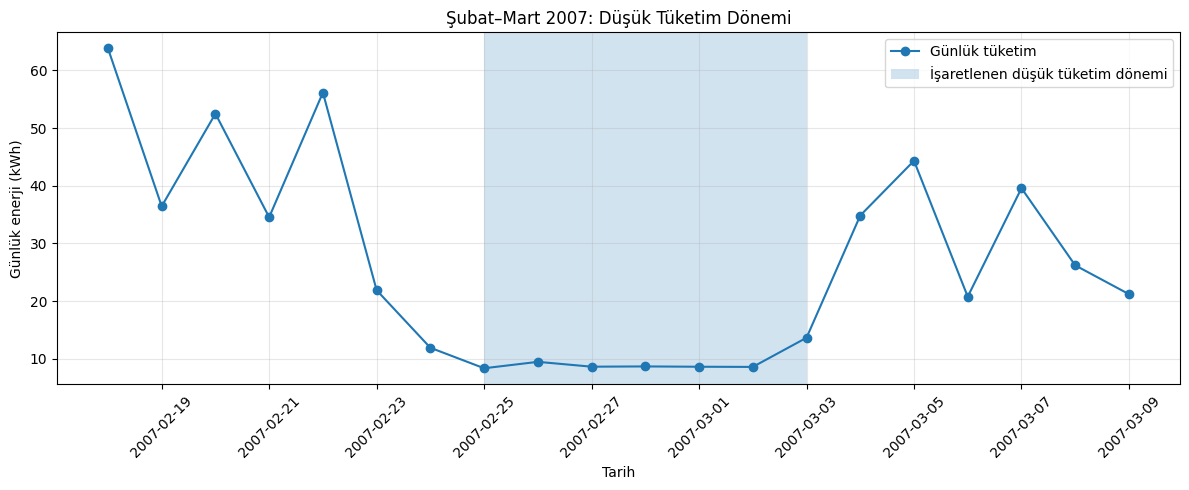

In [18]:

# İncelemek istediğimiz dönemin öncesi ve sonrası
period = daily.loc[
    "2007-02-18":"2007-03-09",
    ["energy_kwh", "measurement_count", "valid_day"]
]

display(period.round(2))

# Günlük tüketimi çiz
plt.figure(figsize=(12, 5))

plt.plot(
    period.index,
    period["energy_kwh"],
    marker="o",
    linewidth=1.5,
    label="Günlük tüketim"
)

# Düşük tüketim dönemini vurgula
plt.axvspan(
    pd.Timestamp("2007-02-25"),
    pd.Timestamp("2007-03-03"),
    alpha=0.2,
    label="İşaretlenen düşük tüketim dönemi"
)

plt.title("Şubat–Mart 2007: Düşük Tüketim Dönemi")
plt.xlabel("Tarih")
plt.ylabel("Günlük enerji (kWh)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/low_consumption_period.png",
    dpi=150
)

plt.show()


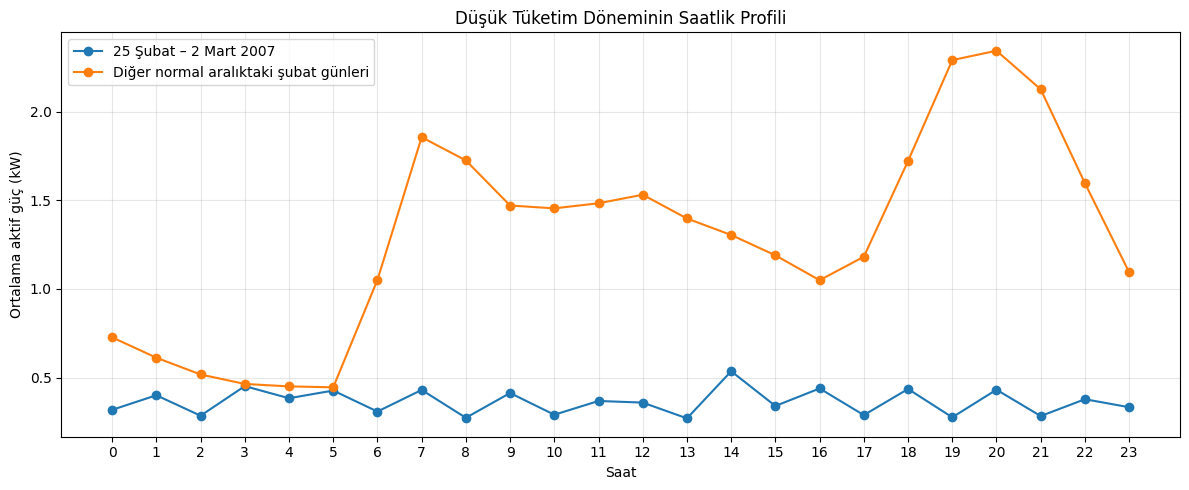

In [19]:

# Düşük tüketim dönemindeki dakikalık ölçümler
low_period = df_clean[
    (df_clean["datetime"] >= "2007-02-25") &
    (df_clean["datetime"] < "2007-03-03")
].copy()

# Aynı ayın diğer geçerli günleriyle karşılaştır
february_normal_dates = monthly_df[
    (monthly_df["month"] == 2) &
    (~monthly_df["monthly_outlier"])
]["datetime"].dt.date

february_normal = df_clean[
    df_clean["datetime"].dt.date.isin(
        february_normal_dates
    )
].copy()

# Saatlik ortalama aktif güç
low_hourly = (
    low_period.groupby("hour")["Global_active_power"]
    .mean()
)

normal_hourly = (
    february_normal.groupby("hour")["Global_active_power"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    low_hourly.index,
    low_hourly.values,
    marker="o",
    label="25 Şubat – 2 Mart 2007"
)

plt.plot(
    normal_hourly.index,
    normal_hourly.values,
    marker="o",
    label="Diğer normal aralıktaki şubat günleri"
)

plt.title("Düşük Tüketim Döneminin Saatlik Profili")
plt.xlabel("Saat")
plt.ylabel("Ortalama aktif güç (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/low_period_hourly.png",
    dpi=150
)

plt.show()


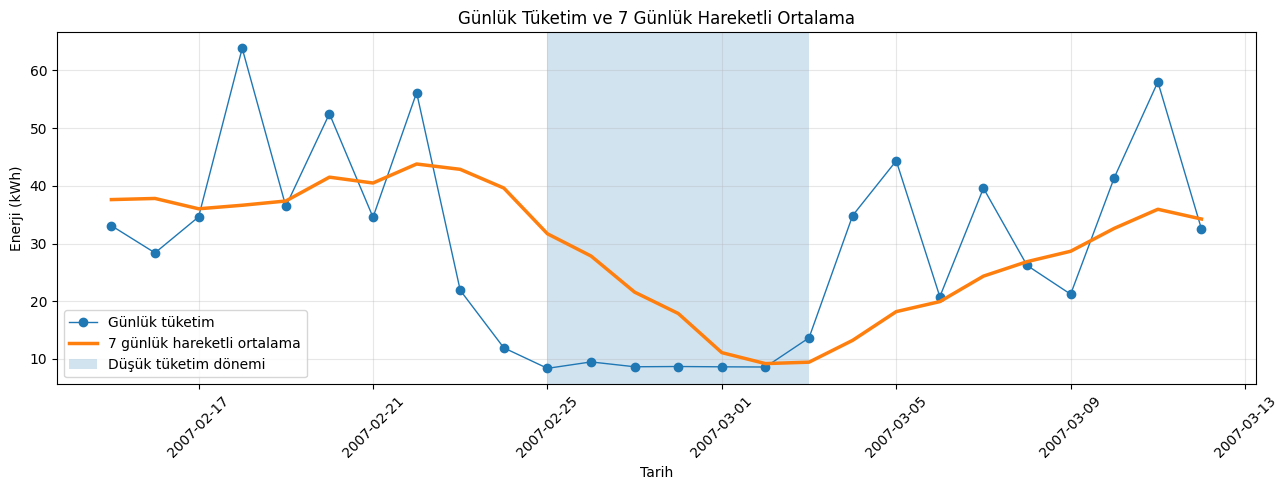

In [20]:

# Geçerli günlük tüketim serisi
daily_energy = daily["energy_kwh"]

# Son 7 takvim gününün ortalaması
# En az 7 geçerli gün bulunmasını şart koşuyoruz
rolling_mean_7d = daily_energy.rolling(
    window=7,
    min_periods=7
).mean()

# İnceleyeceğimiz dönem
start_date = "2007-02-15"
end_date = "2007-03-12"

plt.figure(figsize=(13, 5))

plt.plot(
    daily_energy.loc[start_date:end_date],
    marker="o",
    linewidth=1,
    label="Günlük tüketim"
)

plt.plot(
    rolling_mean_7d.loc[start_date:end_date],
    linewidth=2.5,
    label="7 günlük hareketli ortalama"
)

plt.axvspan(
    pd.Timestamp("2007-02-25"),
    pd.Timestamp("2007-03-03"),
    alpha=0.2,
    label="Düşük tüketim dönemi"
)

plt.title("Günlük Tüketim ve 7 Günlük Hareketli Ortalama")
plt.xlabel("Tarih")
plt.ylabel("Enerji (kWh)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/rolling_mean_7d.png",
    dpi=150
)

plt.show()


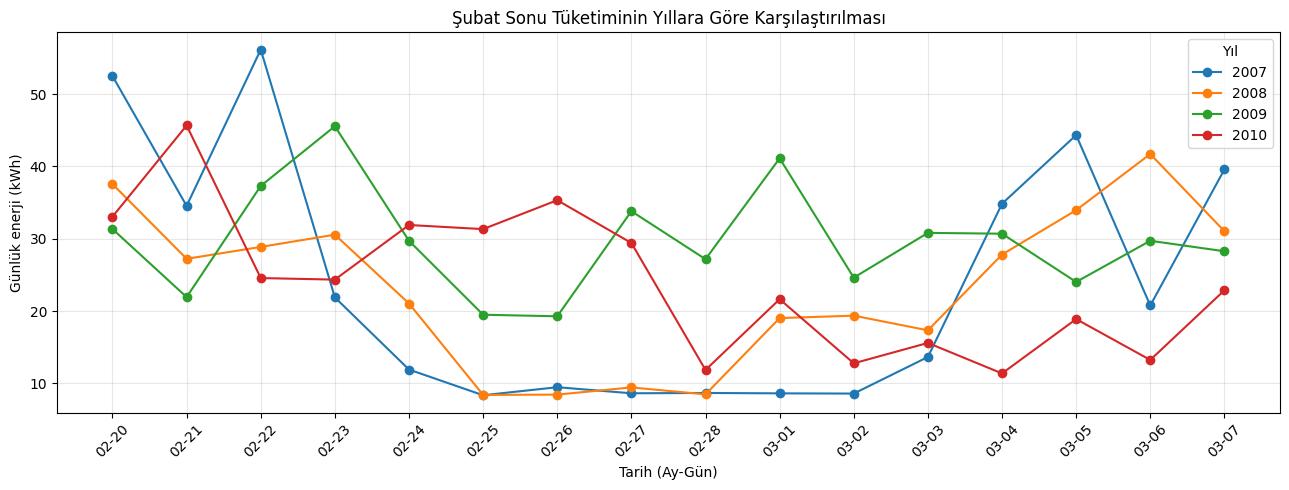

In [21]:

# Bütün yıllarda ortak olan tarihleri oluştur
common_dates = (
    pd.date_range("2007-02-20", "2007-03-07")
    .strftime("%m-%d")
)

plt.figure(figsize=(13, 5))

for year in [2007, 2008, 2009, 2010]:

    year_data = daily.loc[
        f"{year}-02-20":f"{year}-03-07",
        "energy_kwh"
    ].copy()

    # Ay-gün bilgisi
    year_data.index = year_data.index.strftime("%m-%d")

    # Her yılı aynı tarihlere ve aynı sıraya hizala
    # 2008'deki 29 Şubat otomatik olarak çıkarılır
    year_data = year_data.reindex(common_dates)

    plt.plot(
        common_dates,
        year_data.values,
        marker="o",
        linewidth=1.5,
        label=str(year)
    )

plt.title("Şubat Sonu Tüketiminin Yıllara Göre Karşılaştırılması")
plt.xlabel("Tarih (Ay-Gün)")
plt.ylabel("Günlük enerji (kWh)")
plt.xticks(rotation=45)
plt.legend(title="Yıl")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/february_year_comparison.png",
    dpi=150
)

plt.show()


In [22]:

# 2007 ve 2008'deki düşük tüketim dönemlerini
# haftanın günleriyle birlikte incele

for year in [2007, 2008]:
    period = daily.loc[
        f"{year}-02-23":f"{year}-03-04",
        ["energy_kwh", "measurement_count"]
    ].copy()

    period["weekday"] = period.index.day_name()

    print(f"\n{year} yılı:")
    display(period.round(2))



2007 yılı:


,energy_kwh,measurement_count,weekday
datetime,,,
2007-02-23,21.89,1440,Friday
2007-02-24,11.92,1440,Saturday
2007-02-25,8.36,1440,Sunday
2007-02-26,9.47,1440,Monday
2007-02-27,8.64,1440,Tuesday
2007-02-28,8.68,1440,Wednesday
2007-03-01,8.63,1440,Thursday
2007-03-02,8.59,1440,Friday
2007-03-03,13.65,1440,Saturday



2008 yılı:


,energy_kwh,measurement_count,weekday
datetime,,,
2008-02-23,30.57,1438,Saturday
2008-02-24,21.05,1440,Sunday
2008-02-25,8.41,1440,Monday
2008-02-26,8.45,1440,Tuesday
2008-02-27,9.45,1440,Wednesday
2008-02-28,8.49,1440,Thursday
2008-02-29,22.22,1440,Friday
2008-03-01,19.03,1440,Saturday
2008-03-02,19.37,1440,Sunday


## 7. Günlük özellik mühendisliği
Gece/akşam tüketimi, günlük maksimum ve standart sapma ile yalnızca **önceki** yedi takvim gününden oluşturulan geçmiş ortalama hesaplanır. Eksik geçmişi olan günler model tablosuna alınmaz.

In [23]:

# Dakikalık ölçümlerden günlük özellikler
daily_features = (
    df_clean.set_index("datetime")
    .resample("D")
    .agg(
        measurement_count=("Global_active_power", "count"),
        mean_power=("Global_active_power", "mean"),
        max_power=("Global_active_power", "max"),
        std_power=("Global_active_power", "std"),
        total_power=("Global_active_power", "sum")
    )
)

# Günlük enerji tüketimi (kWh)
daily_features["energy_kwh"] = (
    daily_features["total_power"] / 60
)

# Yeterli ölçüme sahip günleri seç
daily_features = daily_features[
    daily_features["measurement_count"] >= 1380
].copy()

# Artık ihtiyacımız olmayan ara toplamı kaldır
daily_features = daily_features.drop(columns=["total_power"])

display(daily_features.head(10))

print("Özellik tablosunun boyutu:", daily_features.shape)
print("Eksik değer sayısı:", daily_features.isna().sum().sum())


,measurement_count,mean_power,max_power,std_power,energy_kwh
datetime,,,,,
2006-12-17,1440,2.354486,7.064,1.205795,56.507667
2006-12-18,1440,1.530435,6.158,1.005074,36.730433
2006-12-19,1440,1.157079,7.840,1.237602,27.769900
2006-12-20,1440,1.545658,5.988,1.320968,37.095800
2006-12-21,1438,1.193758,5.854,0.993432,28.610400
2006-12-22,1440,1.625929,7.884,1.436180,39.022300
2006-12-23,1440,3.314851,8.698,1.503276,79.556433
2006-12-24,1440,1.770842,6.824,1.275370,42.500200
2006-12-25,1440,1.904944,6.702,1.425755,45.718667


Özellik tablosunun boyutu: (1416, 5)
Eksik değer sayısı: 0


In [24]:

# Gece ölçümleri: 00.00–05.59
night_data = df_clean[
    df_clean["hour"].between(0, 5)
]

night_power = (
    night_data
    .set_index("datetime")["Global_active_power"]
    .resample("D")
    .mean()
)

# Akşam ölçümleri: 18.00–22.59
evening_data = df_clean[
    df_clean["hour"].between(18, 22)
]

evening_power = (
    evening_data
    .set_index("datetime")["Global_active_power"]
    .resample("D")
    .mean()
)

# Günlük özellik tablosuna ekle
daily_features["night_mean_power"] = night_power
daily_features["evening_mean_power"] = evening_power

# Akşam / gece tüketim oranı
daily_features["evening_night_ratio"] = (
    daily_features["evening_mean_power"] /
    daily_features["night_mean_power"]
)

display(
    daily_features.loc[
        "2007-02-22":"2007-03-05",
        [
            "energy_kwh",
            "night_mean_power",
            "evening_mean_power",
            "evening_night_ratio"
        ]
    ].round(2)
)

print(
    "\nEksik değerler:",
    daily_features.isna().sum()
)


,energy_kwh,night_mean_power,evening_mean_power,evening_night_ratio
datetime,,,,
2007-02-22,56.16,2.28,3.89,1.70
2007-02-23,21.89,0.42,0.32,0.77
2007-02-24,11.92,0.46,0.30,0.65
2007-02-25,8.36,0.41,0.28,0.68
2007-02-26,9.47,0.43,0.40,0.92
2007-02-27,8.64,0.27,0.47,1.72
2007-02-28,8.68,0.28,0.48,1.68
2007-03-01,8.63,0.43,0.28,0.65
2007-03-02,8.59,0.44,0.27,0.62



Eksik değerler: measurement_count      0
mean_power             0
max_power              0
std_power              0
energy_kwh             0
night_mean_power       0
evening_mean_power     0
evening_night_ratio    0
dtype: int64


In [25]:

# Gece ve akşam saatlerindeki günlük ölçüm sayıları
night_count = (
    night_data
    .set_index("datetime")["Global_active_power"]
    .resample("D")
    .count()
)

evening_count = (
    evening_data
    .set_index("datetime")["Global_active_power"]
    .resample("D")
    .count()
)

# Özellik tablosuna ekle
daily_features["night_count"] = night_count
daily_features["evening_count"] = evening_count

# Beklenen ölçüm sayıları:
# Gece: 6 saat × 60 = 360
# Akşam: 5 saat × 60 = 300

# En az %95 ölçüm bulunan günler
daily_features["night_valid"] = (
    daily_features["night_count"] >= 342
)

daily_features["evening_valid"] = (
    daily_features["evening_count"] >= 285
)

print("Yetersiz gece ölçümü bulunan gün:",
      (~daily_features["night_valid"]).sum())

print("Yetersiz akşam ölçümü bulunan gün:",
      (~daily_features["evening_valid"]).sum())

display(
    daily_features.loc[
        ~(daily_features["night_valid"] &
          daily_features["evening_valid"]),
        ["measurement_count", "night_count",
         "evening_count", "night_valid", "evening_valid"]
    ].head(15)
)


Yetersiz gece ölçümü bulunan gün: 0
Yetersiz akşam ölçümü bulunan gün: 1


,measurement_count,night_count,evening_count,night_valid,evening_valid
datetime,,,,,
2007-06-09,1402,360,268,True,False


In [26]:

# Geçmiş ortalamayı hesaplamak için bütün takvim günlerini
# içeren daily tablosunu kullanıyoruz.
# Böylece eksik günleri yanlışlıkla atlayıp
# daha eski günleri yedi günlük pencereye dahil etmiyoruz.

previous_7d_mean = (
    daily["energy_kwh"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

# Yeni özellikleri mevcut tabloya ekle
daily_features["previous_7d_mean"] = previous_7d_mean

daily_features["change_from_7d_pct"] = (
    (
        daily_features["energy_kwh"]
        - daily_features["previous_7d_mean"]
    )
    / daily_features["previous_7d_mean"]
    * 100
)

# İncelediğimiz düşük tüketim dönemine bakalım
display(
    daily_features.loc[
        "2007-02-20":"2007-03-05",
        [
            "energy_kwh",
            "previous_7d_mean",
            "change_from_7d_pct"
        ]
    ].round(2)
)

print(
    "\nGeçmiş ortalaması hesaplanamayan gün:",
    daily_features["previous_7d_mean"].isna().sum()
)


,energy_kwh,previous_7d_mean,change_from_7d_pct
datetime,,,
2007-02-20,52.50,37.37,40.49
2007-02-21,34.55,41.50,-16.75
2007-02-22,56.16,40.49,38.71
2007-02-23,21.89,43.78,-50.00
2007-02-24,11.92,42.85,-72.20
2007-02-25,8.36,39.61,-78.89
2007-02-26,9.47,31.69,-70.10
2007-02-27,8.64,27.84,-68.98
2007-02-28,8.68,21.57,-59.76



Geçmiş ortalaması hesaplanamayan gün: 70


In [27]:

# Modelde kullanacağımız tüketim özellikleri
feature_cols = [
    "energy_kwh",
    "max_power",
    "std_power",
    "night_mean_power",
    "evening_mean_power",
    "evening_night_ratio",
    "previous_7d_mean",
    "change_from_7d_pct"
]

# Gece ve akşam ölçümleri yeterli olan günleri seç
quality_mask = (
    daily_features["night_valid"]
    & daily_features["evening_valid"]
)

# Model için ayrı bir tablo oluştur
model_df = daily_features.loc[
    quality_mask, feature_cols
].copy()

print("Kalite kontrolünden geçen gün:", len(model_df))
print("Eksik özelliği olan gün:",
      model_df.isna().any(axis=1).sum())

# Eksik geçmiş ortalaması bulunan günleri
# yalnızca model tablosundan çıkar
model_df = model_df.dropna()

print("Modele hazır gün:", len(model_df))
print("Özellik sayısı:", model_df.shape[1])

display(model_df.head())


Kalite kontrolünden geçen gün: 1415
Eksik özelliği olan gün: 70
Modele hazır gün: 1345
Özellik sayısı: 8


,energy_kwh,max_power,std_power,night_mean_power,evening_mean_power,evening_night_ratio,previous_7d_mean,change_from_7d_pct
datetime,,,,,,,,
2006-12-24,42.500200,6.824,1.275370,2.403583,0.479427,0.199463,43.613276,-2.552150
2006-12-25,45.718667,6.702,1.425755,0.738844,2.816287,3.811745,41.612210,9.868395
2006-12-26,65.568500,6.496,0.957549,2.511189,2.656340,1.057802,42.896243,52.853713
2006-12-27,25.479333,5.560,0.825595,0.568439,1.665400,2.929778,48.296043,-47.243435
2006-12-28,34.543967,9.132,1.436292,0.418456,3.151740,7.531839,46.636548,-25.929409


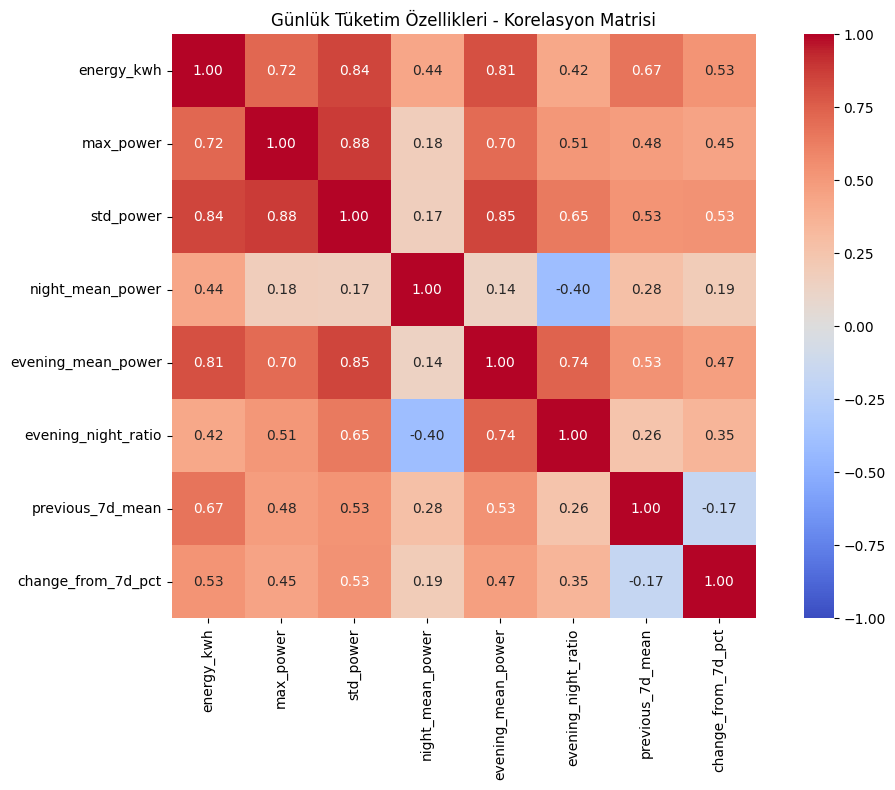

Mutlak korelasyonu 0.80 ve üzeri olan çiftler:


max_power   std_power             0.877611
std_power   evening_mean_power    0.849146
energy_kwh  std_power             0.844411
            evening_mean_power    0.809891
dtype: float64

In [28]:

import seaborn as sns
import matplotlib.pyplot as plt

# Özellikler arasındaki Pearson korelasyonu
correlation = model_df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Günlük Tüketim Özellikleri - Korelasyon Matrisi")
plt.tight_layout()
plt.show()

# Güçlü ilişkileri ayrıca listele
pairs = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
).stack()

print("Mutlak korelasyonu 0.80 ve üzeri olan çiftler:")
display(
    pairs[pairs.abs() >= 0.80]
    .sort_values(key=abs, ascending=False)
)


## 8. Ana model: Isolation Forest (%3)
Ana model altı özellik, 200 ağaç ve `random_state=42` kullanır. Sonuçlar **aynı eğitim verisi üzerindeki keşifsel skorlar**dır; bağımsız test başarısı veya gerçek anomali doğruluğu değildir.

In [29]:

from sklearn.ensemble import IsolationForest

# İlk modelimizin özellikleri
selected_features = [
    "energy_kwh",
    "max_power",
    "night_mean_power",
    "evening_mean_power",
    "previous_7d_mean",
    "change_from_7d_pct"
]

X = model_df[selected_features].copy()

# İlk Isolation Forest modeli
iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)

# Modeli eğit
iso_model.fit(X)

# Sonuçları ayrı bir tabloya kaydet
results = X.copy()

# -1: Anomali adayı, 1: Normal olarak işaretlenen
results["prediction"] = iso_model.predict(X)

# Düşük skor = daha anormal
results["anomaly_score"] = iso_model.decision_function(X)

# Anomali adaylarını ayır
anomalies = results[
    results["prediction"] == -1
].sort_values("anomaly_score")

print("İncelenen gün:", len(results))
print("Anomali adayı:", len(anomalies))

display(anomalies.head(15).round(2))


İncelenen gün: 1345
Anomali adayı: 41


,energy_kwh,max_power,night_mean_power,evening_mean_power,previous_7d_mean,change_from_7d_pct,prediction,anomaly_score
datetime,,,,,,,,
2007-02-03,67.16,7.90,2.93,4.28,34.95,92.14,-1,-0.12
2007-03-04,34.84,10.67,0.28,3.78,9.43,269.43,-1,-0.11
2007-03-05,44.34,9.49,0.31,3.78,13.22,235.51,-1,-0.10
2006-12-26,65.57,6.50,2.51,2.66,42.90,52.85,-1,-0.09
2007-02-22,56.16,9.41,2.28,3.89,40.49,38.71,-1,-0.09
2007-01-01,45.82,3.56,2.52,0.70,46.99,-2.50,-1,-0.07
2007-02-04,59.93,7.70,2.92,2.58,39.68,51.03,-1,-0.07
2007-03-11,58.01,7.14,2.42,3.26,32.62,77.81,-1,-0.06
2008-11-23,56.76,8.56,0.80,4.74,29.90,89.85,-1,-0.06


In [30]:

# Modelin işaretlediği bütün günleri al
anomaly_summary = anomalies.copy()

# Tarihten yıl ve ay bilgilerini çıkar
anomaly_summary["year"] = anomaly_summary.index.year
anomaly_summary["month"] = anomaly_summary.index.month

# Her yılda kaç gün incelendi ve kaçı işaretlendi?
yearly_summary = results.groupby(
    results.index.year
).agg(
    examined_days=("prediction", "size"),
    anomaly_days=("prediction", lambda x: (x == -1).sum())
)

yearly_summary["anomaly_rate_pct"] = (
    yearly_summary["anomaly_days"]
    / yearly_summary["examined_days"]
    * 100
)

print("Yıllara göre model sonuçları:")
display(yearly_summary.round(2))

print("\nYıl ve aylara göre anomali sayıları:")
display(
    pd.crosstab(
        anomaly_summary["year"],
        anomaly_summary["month"]
    )
)

# İşaretlenen bütün günleri kronolojik sırayla göster
print("\nAnomali adayları:")
display(
    anomaly_summary[
        ["energy_kwh",
         "change_from_7d_pct",
         "anomaly_score"]
    ].sort_index().round(2)
)


Yıllara göre model sonuçları:


,examined_days,anomaly_days,anomaly_rate_pct
datetime,,,
2006,8,4,50.00
2007,346,18,5.20
2008,358,14,3.91
2009,347,5,1.44
2010,286,0,0.00



Yıl ve aylara göre anomali sayıları:


month,1,2,3,7,8,9,11,12
year,,,,,,,,
2006,0,0,0,0,0,0,0,4
2007,5,7,5,0,0,0,0,1
2008,2,0,0,0,7,1,3,1
2009,2,2,0,1,0,0,0,0



Anomali adayları:


,energy_kwh,change_from_7d_pct,anomaly_score
datetime,,,
2006-12-24,42.50,-2.55,-0.04
2006-12-26,65.57,52.85,-0.09
2006-12-29,52.91,11.42,-0.05
2006-12-31,58.24,30.16,-0.00
2007-01-01,45.82,-2.50,-0.07
2007-01-04,54.32,37.75,-0.05
2007-01-05,45.22,7.01,-0.02
2007-01-13,53.11,60.05,-0.02
2007-01-21,56.79,47.90,-0.03


,energy_kwh,measurement_count,night_mean_power,evening_mean_power,previous_7d_mean,change_from_7d_pct,anomaly_score,is_anomaly
datetime,,,,,,,,
2008-08-15,4.56,1440,0.19,0.20,5.30,-13.98,0.01,False
2008-08-16,4.58,1440,0.19,0.20,5.23,-12.49,0.01,False
2008-08-17,4.58,1440,0.19,0.20,5.03,-9.02,0.01,False
2008-08-18,4.56,1440,0.19,0.20,4.85,-5.93,0.01,False
2008-08-19,4.58,1440,0.20,0.19,4.62,-0.83,0.01,False
2008-08-20,4.47,1440,0.19,0.19,4.58,-2.35,0.01,False
2008-08-21,4.35,1440,0.18,0.18,4.55,-4.26,0.00,False
2008-08-22,4.45,1440,0.19,0.19,4.53,-1.66,0.00,False
2008-08-23,4.24,1440,0.18,0.18,4.51,-5.93,0.00,False


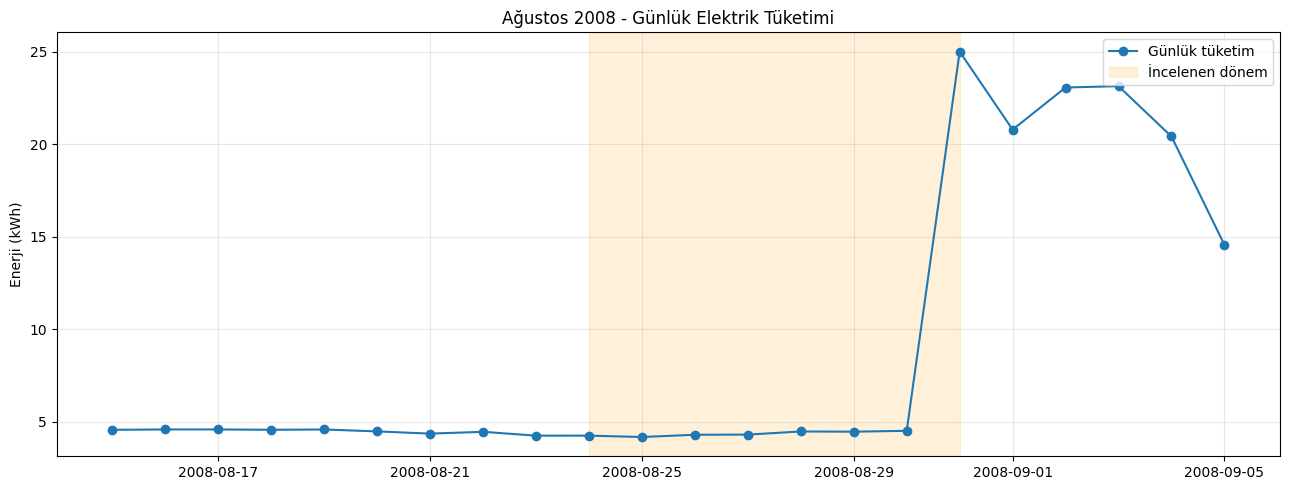

In [31]:

# Ağustos 2008'deki düşük tüketim dönemini incele
august_period = daily_features.loc[
    "2008-08-15":"2008-09-05",
    [
        "energy_kwh",
        "measurement_count",
        "night_mean_power",
        "evening_mean_power",
        "previous_7d_mean",
        "change_from_7d_pct"
    ]
].copy()

# Modelin kararlarını ekle
august_period["anomaly_score"] = results[
    "anomaly_score"
].reindex(august_period.index)

august_period["is_anomaly"] = (
    results["prediction"]
    .reindex(august_period.index)
    .eq(-1)
)

display(august_period.round(2))

# Günlük tüketimi görselleştir
plt.figure(figsize=(13, 5))

plt.plot(
    august_period.index,
    august_period["energy_kwh"],
    marker="o",
    label="Günlük tüketim"
)

plt.axvspan(
    pd.Timestamp("2008-08-24"),
    pd.Timestamp("2008-08-31"),
    color="orange",
    alpha=0.15,
    label="İncelenen dönem"
)

plt.ylabel("Enerji (kWh)")
plt.title("Ağustos 2008 - Günlük Elektrik Tüketimi")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,examined_days,mean_energy,median_energy,min_energy,max_energy,mean_score,min_score,anomaly_days
year,,,,,,,,
2006,8,46.430,46.104,25.479,65.568,-0.001,-0.090,4
2007,346,27.152,26.030,5.352,67.162,0.136,-0.121,18
2008,358,25.606,26.346,4.172,56.755,0.152,-0.059,14
2009,347,26.230,25.812,8.162,55.297,0.173,-0.016,5
2010,286,25.148,25.168,8.746,48.384,0.168,0.022,0


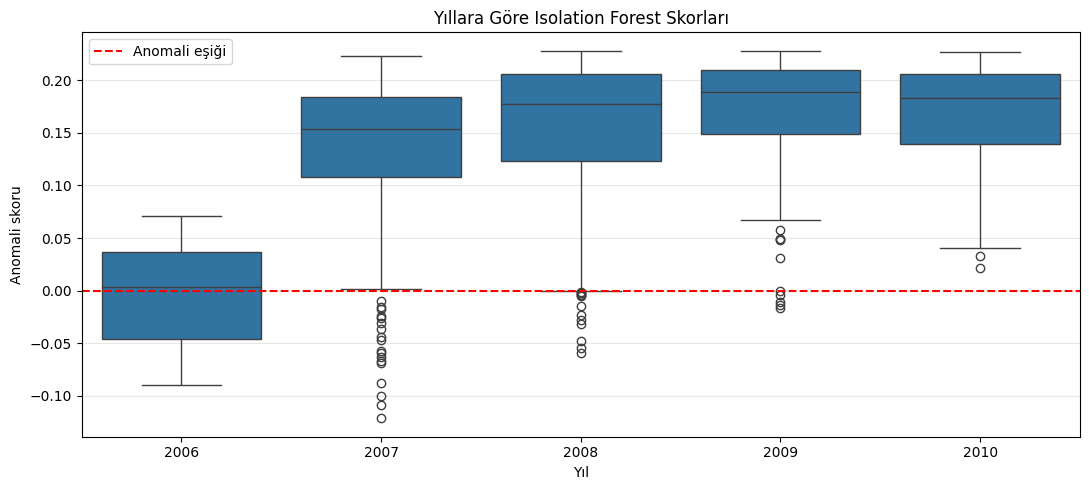

In [32]:

# Model sonuçlarına yıl bilgisini ekle
year_analysis = results.copy()
year_analysis["year"] = year_analysis.index.year

# Yıllık tüketim ve skor istatistikleri
yearly_stats = year_analysis.groupby("year").agg(
    examined_days=("energy_kwh", "size"),
    mean_energy=("energy_kwh", "mean"),
    median_energy=("energy_kwh", "median"),
    min_energy=("energy_kwh", "min"),
    max_energy=("energy_kwh", "max"),
    mean_score=("anomaly_score", "mean"),
    min_score=("anomaly_score", "min"),
    anomaly_days=("prediction", lambda x: (x == -1).sum())
)

display(yearly_stats.round(3))

# Yıllara göre anomali skoru dağılımı
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=year_analysis,
    x="year",
    y="anomaly_score"
)

# Isolation Forest karar eşiği
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Anomali eşiği"
)

plt.title("Yıllara Göre Isolation Forest Skorları")
plt.xlabel("Yıl")
plt.ylabel("Anomali skoru")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


,examined_days,mean_energy,median_energy,min_energy,max_energy,anomaly_days,anomaly_rate_pct
month,,,,,,,
1,114,35.02,33.40,16.90,56.79,9,7.89
2,113,31.20,31.29,8.36,67.16,9,7.96
3,115,29.55,29.57,8.59,58.49,5,4.35
4,117,25.16,25.65,8.96,46.67,0,0.00
5,117,24.75,24.96,9.60,36.47,0,0.00
6,109,22.08,21.68,7.96,38.15,0,0.00
7,116,16.88,17.14,5.35,30.08,1,0.86
8,103,13.04,12.33,4.17,27.81,7,6.80
9,114,23.39,22.99,14.57,38.28,1,0.88


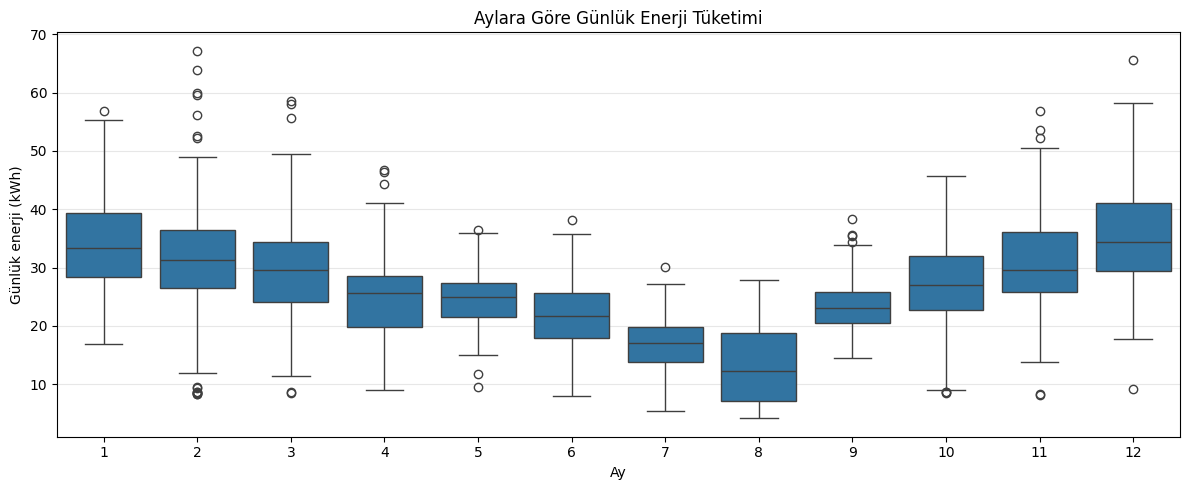

In [33]:

# Model sonuçlarına ay bilgisini ekle
monthly_analysis = results.copy()
monthly_analysis["month"] = monthly_analysis.index.month

# Aylık tüketim ve anomali istatistikleri
monthly_stats = monthly_analysis.groupby("month").agg(
    examined_days=("energy_kwh", "size"),
    mean_energy=("energy_kwh", "mean"),
    median_energy=("energy_kwh", "median"),
    min_energy=("energy_kwh", "min"),
    max_energy=("energy_kwh", "max"),
    anomaly_days=("prediction", lambda x: (x == -1).sum())
)

monthly_stats["anomaly_rate_pct"] = (
    monthly_stats["anomaly_days"]
    / monthly_stats["examined_days"]
    * 100
)

display(monthly_stats.round(2))

# Aylara göre günlük tüketim dağılımı
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=monthly_analysis,
    x="month",
    y="energy_kwh"
)

plt.title("Aylara Göre Günlük Enerji Tüketimi")
plt.xlabel("Ay")
plt.ylabel("Günlük enerji (kWh)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Isolation Forest ve aylık IQR karşılaştırması
İki yöntemin ortak ve birbirinden farklı işaretlediği günleri inceliyoruz.

In [34]:

# Önceki aylık IQR analizinden sonuçları al
iqr_comparison = monthly_df[
    ["datetime", "energy_kwh", "monthly_outlier"]
].copy()

iqr_comparison = iqr_comparison.set_index("datetime")

# Isolation Forest sonuçlarıyla aynı günleri eşleştir
comparison = results[
    ["energy_kwh", "prediction", "anomaly_score"]
].copy()

comparison["if_anomaly"] = comparison["prediction"] == -1

comparison["iqr_anomaly"] = (
    iqr_comparison["monthly_outlier"]
    .reindex(comparison.index)
)

# Her iki yöntemin kararlarını karşılaştır
print("Kararların karşılaştırılması:")

display(
    pd.crosstab(
        comparison["iqr_anomaly"],
        comparison["if_anomaly"],
        rownames=["Aylık IQR"],
        colnames=["Isolation Forest"]
    )
)

# Her iki yöntemin de işaretlediği günler
both_anomalies = comparison[
    comparison["iqr_anomaly"]
    & comparison["if_anomaly"]
].sort_values("anomaly_score")

print("\nİki yöntemin de işaretlediği gün sayısı:",
      len(both_anomalies))

display(both_anomalies.round(3))


Kararların karşılaştırılması:


Isolation Forest,False,True
Aylık IQR,,
False,1270,26
True,34,15



İki yöntemin de işaretlediği gün sayısı: 15


,energy_kwh,prediction,anomaly_score,if_anomaly,iqr_anomaly
datetime,,,,,
2007-02-03,67.162,-1,-0.121,True,True
2006-12-26,65.568,-1,-0.090,True,True
2007-02-22,56.158,-1,-0.088,True,True
2007-02-04,59.932,-1,-0.067,True,True
2007-03-11,58.011,-1,-0.063,True,True
2008-11-23,56.755,-1,-0.059,True,True
2007-02-18,63.829,-1,-0.057,True,True
2008-11-05,52.249,-1,-0.047,True,True
2007-03-25,55.602,-1,-0.044,True,True


In [35]:

# Yalnızca Isolation Forest'ın işaretlediği günler
if_only = comparison[
    comparison["if_anomaly"]
    & ~comparison["iqr_anomaly"]
].copy()

# Yalnızca aylık IQR'nin işaretlediği günler
iqr_only = comparison[
    comparison["iqr_anomaly"]
    & ~comparison["if_anomaly"]
].copy()

# Modelde kullandığımız ek özellikleri getir
extra_cols = [
    "max_power",
    "night_mean_power",
    "evening_mean_power",
    "previous_7d_mean",
    "change_from_7d_pct"
]

if_only = if_only.join(model_df[extra_cols])
iqr_only = iqr_only.join(model_df[extra_cols])

print("Yalnızca Isolation Forest:", len(if_only))
display(
    if_only.sort_values("anomaly_score")[
        ["energy_kwh",
         "night_mean_power",
         "evening_mean_power",
         "change_from_7d_pct",
         "anomaly_score"]
    ].round(3)
)

print("\nYalnızca aylık IQR:", len(iqr_only))
display(
    iqr_only.sort_values("energy_kwh")[
        ["energy_kwh",
         "night_mean_power",
         "evening_mean_power",
         "change_from_7d_pct",
         "anomaly_score"]
    ].round(3)
)


Yalnızca Isolation Forest: 26


,energy_kwh,night_mean_power,evening_mean_power,change_from_7d_pct,anomaly_score
datetime,,,,,
2007-03-04,34.845,0.281,3.782,269.430,-0.109
2007-03-05,44.339,0.306,3.780,235.511,-0.100
2007-01-01,45.817,2.525,0.697,-2.500,-0.069
2007-12-29,54.983,2.336,3.329,26.892,-0.059
2008-08-31,25.010,0.199,2.367,474.964,-0.055
2006-12-29,52.907,2.144,3.027,11.419,-0.050
2007-01-04,54.324,2.623,1.571,37.754,-0.047
2006-12-24,42.500,2.404,0.479,-2.552,-0.045
2008-12-27,49.536,2.441,2.615,69.776,-0.031



Yalnızca aylık IQR: 34


,energy_kwh,night_mean_power,evening_mean_power,change_from_7d_pct,anomaly_score
datetime,,,,,
2007-11-03,8.209,0.262,0.448,-49.866,0.080
2007-11-01,8.270,0.268,0.451,-57.789,0.074
2007-02-25,8.362,0.407,0.276,-78.889,0.001
2008-02-25,8.408,0.394,0.264,-71.425,0.037
2008-02-26,8.452,0.434,0.269,-68.720,0.047
2008-02-28,8.486,0.267,0.472,-55.678,0.073
2007-10-28,8.536,0.383,0.286,-71.301,0.040
2007-03-02,8.595,0.442,0.272,-22.454,0.080
2007-03-01,8.626,0.428,0.277,-51.739,0.075


## 10. Ardışık düşük tüketim olayları
Takvim ayı medyanına göre eşik altında en az üç ardışık takvim günü süren dönemleri tespit ediyoruz. Aylık medyanlar incelenen verinin kendisinden hesaplandığı için bu da veri içi, açıklayıcı bir karşılaştırmadır.

In [36]:

# Aylık medyanları hesapla
monthly_medians = (
    monthly_analysis.groupby("month")["energy_kwh"].median()
)

# Günleri kendi aylarının medyanıyla karşılaştır
events_df = monthly_analysis[
    ["energy_kwh", "prediction"]
].copy()

events_df["month"] = events_df.index.month

events_df["monthly_median"] = (
    events_df["month"].map(monthly_medians)
)

events_df["low_consumption"] = (
    events_df["energy_kwh"]
    < events_df["monthly_median"] * 0.5
)

events_df["if_anomaly"] = events_df["prediction"] == -1

# Yalnızca ardışık takvim günlerini aynı olayda birleştir
date_gap = events_df.index.to_series().diff().dt.days.ne(1)

state_change = (
    events_df["low_consumption"]
    != events_df["low_consumption"].shift()
)

events_df["event_id"] = (
    date_gap | state_change
).cumsum()

# En az 3 gün süren düşük tüketim olayları
low_events = (
    events_df[events_df["low_consumption"]]
    .groupby("event_id")
    .agg(
        start=("energy_kwh", lambda x: x.index.min()),
        end=("energy_kwh", lambda x: x.index.max()),
        duration_days=("energy_kwh", "size"),
        mean_energy=("energy_kwh", "mean"),
        if_flagged_days=("if_anomaly", "sum")
    )
)

low_events = low_events[
    low_events["duration_days"] >= 3
].copy()

low_events["if_coverage_pct"] = (
    low_events["if_flagged_days"]
    / low_events["duration_days"]
    * 100
)

print("Bulunan düşük tüketim dönemi:", len(low_events))

display(
    low_events.sort_values(
        "duration_days", ascending=False
    ).round(2)
)


Bulunan düşük tüketim dönemi: 6


,start,end,duration_days,mean_energy,if_flagged_days,if_coverage_pct
event_id,,,,,,
33,2008-08-12,2008-08-30,19,4.47,6,31.58
2,2007-02-24,2007-03-03,8,9.74,1,12.50
31,2008-08-06,2008-08-10,5,5.58,0,0.00
4,2007-04-12,2007-04-15,4,9.87,0,0.00
25,2008-02-25,2008-02-28,4,8.70,0,0.00
44,2009-02-17,2009-02-19,3,13.03,0,0.00


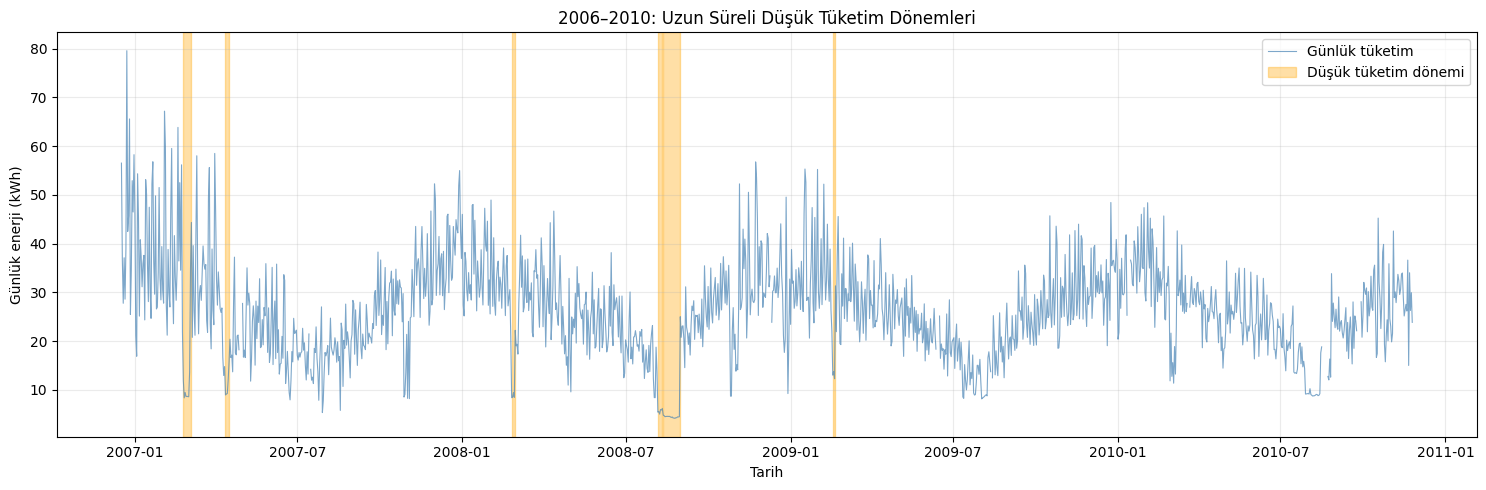

,energy_kwh,measurement_count,valid_day
datetime,,,
2008-08-06,5.44,1440,True
2008-08-07,5.58,1440,True
2008-08-08,5.04,1440,True
2008-08-09,5.98,1440,True
2008-08-10,5.87,1440,True
2008-08-11,6.20,1440,True
2008-08-12,4.82,1440,True


In [37]:

fig, ax = plt.subplots(figsize=(15, 5))

# Tüm günlük tüketim verileri
ax.plot(
    daily.index,
    daily["energy_kwh"],
    color="steelblue",
    linewidth=0.8,
    alpha=0.7,
    label="Günlük tüketim"
)

# Altı düşük tüketim dönemini işaretle
for i, (_, event) in enumerate(low_events.iterrows()):
    ax.axvspan(
        event["start"],
        event["end"] + pd.Timedelta(days=1),
        color="orange",
        alpha=0.35,
        label="Düşük tüketim dönemi" if i == 0 else None
    )

ax.set_title("2006–2010: Uzun Süreli Düşük Tüketim Dönemleri")
ax.set_xlabel("Tarih")
ax.set_ylabel("Günlük enerji (kWh)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Ağustos 2008'de iki dönemin arasındaki günü kontrol et
display(
    daily.loc[
        "2008-08-06":"2008-08-12",
        ["energy_kwh", "measurement_count", "valid_day"]
    ].round(2)
)


In [38]:

# 2008'de iki düşük tüketim döneminin arası
august_2008 = daily.loc[
    "2008-08-06":"2008-08-12",
    ["energy_kwh", "measurement_count", "valid_day"]
].copy()

august_median = monthly_medians.loc[8]
august_2008["monthly_median"] = august_median
august_2008["median_ratio"] = (
    august_2008["energy_kwh"] / august_median
)

print("Ağustos 2008:")
display(august_2008.round(2))

# 2010 yazındaki düşük tüketim dönemi
summer_2010 = daily.loc[
    "2010-07-15":"2010-09-15",
    ["energy_kwh", "measurement_count", "valid_day"]
].copy()

summer_2010["month"] = summer_2010.index.month
summer_2010["monthly_median"] = (
    summer_2010["month"].map(monthly_medians)
)

summer_2010["median_ratio"] = (
    summer_2010["energy_kwh"]
    / summer_2010["monthly_median"]
)

print("\n2010 yazı - en düşük tüketimli 15 gün:")
display(
    summer_2010.sort_values("energy_kwh")
    .head(15)
    .round(2)
)


Ağustos 2008:


,energy_kwh,measurement_count,valid_day,monthly_median,median_ratio
datetime,,,,,
2008-08-06,5.44,1440,True,12.33,0.44
2008-08-07,5.58,1440,True,12.33,0.45
2008-08-08,5.04,1440,True,12.33,0.41
2008-08-09,5.98,1440,True,12.33,0.49
2008-08-10,5.87,1440,True,12.33,0.48
2008-08-11,6.20,1440,True,12.33,0.50
2008-08-12,4.82,1440,True,12.33,0.39



2010 yazı - en düşük tüketimli 15 gün:


,energy_kwh,measurement_count,valid_day,month,monthly_median,median_ratio
datetime,,,,,,
2010-08-06,8.75,1440,True,8,12.33,0.71
2010-08-07,8.79,1440,True,8,12.33,0.71
2010-08-08,8.81,1440,True,8,12.33,0.71
2010-08-12,8.83,1440,True,8,12.33,0.72
2010-08-05,8.89,1440,True,8,12.33,0.72
2010-08-13,8.90,1440,True,8,12.33,0.72
2010-08-09,8.92,1440,True,8,12.33,0.72
2010-08-11,9.03,1440,True,8,12.33,0.73
2010-08-04,9.06,1440,True,8,12.33,0.73


## 11. Düşük tüketim eşiği duyarlılığı ve veri kalitesi
%50, %60 ve %75 eşiklerini karşılaştırıyoruz. Nihai olay değerlendirmesinde %60 eşiği kullanılır. Günlük kayıt sayısı tam olsa bile bu, sayaç verisinin fiziksel doğruluğunu tek başına kanıtlamaz.

In [39]:

def find_low_consumption_events(data, threshold=0.5, min_days=3):
    df_events = data[["energy_kwh", "month"]].copy()

    # Her günü kendi ayının medyanıyla karşılaştır
    df_events["monthly_median"] = (
        df_events["month"].map(monthly_medians)
    )

    df_events["is_low"] = (
        df_events["energy_kwh"]
        < df_events["monthly_median"] * threshold
    )

    # Ardışık takvim günlerini kontrol et
    date_gap = (
        df_events.index.to_series()
        .diff()
        .dt.days.ne(1)
    )

    state_change = (
        df_events["is_low"]
        != df_events["is_low"].shift()
    )

    df_events["event_id"] = (
        date_gap | state_change
    ).cumsum()

    events = (
        df_events[df_events["is_low"]]
        .groupby("event_id")
        .agg(
            start=("energy_kwh", lambda x: x.index.min()),
            end=("energy_kwh", lambda x: x.index.max()),
            duration_days=("energy_kwh", "size"),
            mean_energy=("energy_kwh", "mean")
        )
    )

    return events[
        events["duration_days"] >= min_days
    ].copy()


# Üç farklı eşikle aynı veri setini analiz et
for threshold in [0.50, 0.60, 0.75]:
    events = find_low_consumption_events(
        monthly_analysis,
        threshold=threshold,
        min_days=3
    )

    print(f"\nMedyanın %{threshold * 100:.0f}'si:")
    print("Bulunan dönem:", len(events))
    print("Toplam dönem günü:", events["duration_days"].sum())

    # Özellikle Ağustos 2008 ve 2010'u göster
    august_events = events[
        (events["start"].dt.month == 8)
        & (events["start"].dt.year.isin([2008, 2010]))
    ]

    display(august_events.round(2))



Medyanın %50'si:
Bulunan dönem: 6
Toplam dönem günü: 43


,start,end,duration_days,mean_energy
event_id,,,,
31,2008-08-06,2008-08-10,5,5.58
33,2008-08-12,2008-08-30,19,4.47



Medyanın %60'si:
Bulunan dönem: 11
Toplam dönem günü: 64


,start,end,duration_days,mean_energy
event_id,,,,
43,2008-08-06,2008-08-30,25,4.76



Medyanın %75'si:
Bulunan dönem: 19
Toplam dönem günü: 115


,start,end,duration_days,mean_energy
event_id,,,,
100,2008-08-06,2008-08-30,25,4.76
195,2010-08-04,2010-08-14,11,8.94


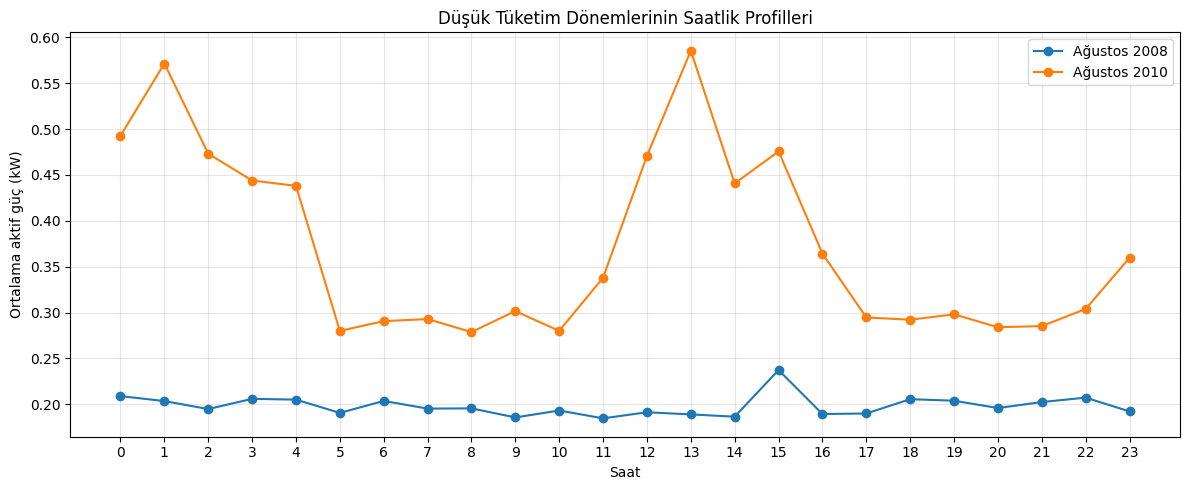

In [40]:
periods = {
    "Ağustos 2008": ("2008-08-06", "2008-08-31"),
    "Ağustos 2010": ("2010-08-04", "2010-08-15")
}

plt.figure(figsize=(12, 5))

for label, (start, end) in periods.items():
    period_data = df_clean[
        (df_clean["datetime"] >= start) &
        (df_clean["datetime"] < end)
    ].copy()

    hourly_profile = (
        period_data
        .groupby(period_data["datetime"].dt.hour)
        ["Global_active_power"]
        .mean()
    )

    plt.plot(
        hourly_profile.index,
        hourly_profile.values,
        marker="o",
        label=label
    )

plt.title("Düşük Tüketim Dönemlerinin Saatlik Profilleri")
plt.xlabel("Saat")
plt.ylabel("Ortalama aktif güç (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

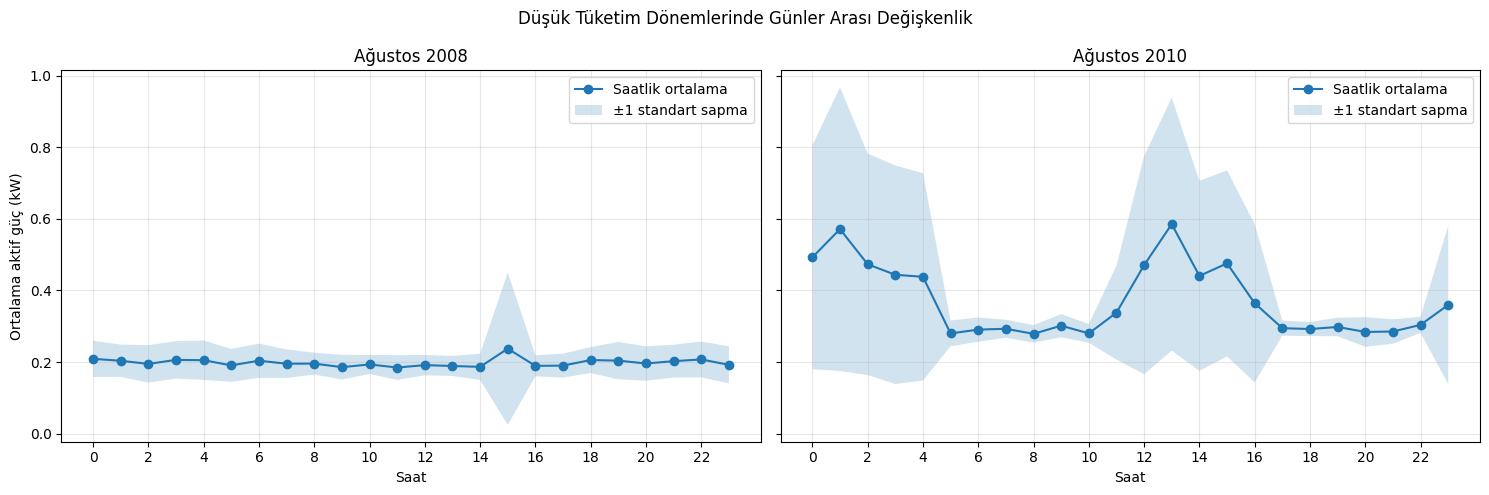

In [41]:
# İki dönemin saatlik ortalamasını ve
# günler arasındaki değişkenliğini karşılaştır

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, (label, (start, end)) in zip(axes, periods.items()):
    period_data = df_clean[
        (df_clean["datetime"] >= start) &
        (df_clean["datetime"] < end)
    ].copy()

    period_data["date"] = period_data["datetime"].dt.date
    period_data["hour"] = period_data["datetime"].dt.hour

    # Her günün her saatindeki ortalama güç
    daily_hourly = period_data.pivot_table(
        index="date",
        columns="hour",
        values="Global_active_power",
        aggfunc="mean"
    )

    hourly_mean = daily_hourly.mean(axis=0)
    hourly_std = daily_hourly.std(axis=0)

    ax.plot(
        hourly_mean.index,
        hourly_mean.values,
        marker="o",
        label="Saatlik ortalama"
    )

    ax.fill_between(
        hourly_mean.index,
        hourly_mean - hourly_std,
        hourly_mean + hourly_std,
        alpha=0.2,
        label="±1 standart sapma"
    )

    ax.set_title(label)
    ax.set_xlabel("Saat")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Ortalama aktif güç (kW)")
plt.suptitle("Düşük Tüketim Dönemlerinde Günler Arası Değişkenlik")
plt.tight_layout()
plt.show()

In [42]:
# İki dönemin günler arası değişkenliğini sayısallaştır

comparison = []

for label, (start, end) in periods.items():
    period_data = df_clean[
        (df_clean["datetime"] >= start) &
        (df_clean["datetime"] < end)
    ].copy()

    period_data["date"] = period_data["datetime"].dt.date
    period_data["hour"] = period_data["datetime"].dt.hour

    daily_hourly = period_data.pivot_table(
        index="date",
        columns="hour",
        values="Global_active_power",
        aggfunc="mean"
    )

    hourly_std = daily_hourly.std(axis=0)
    hourly_mean = daily_hourly.mean(axis=0)

    comparison.append({
        "period": label,
        "days": len(daily_hourly),
        "mean_power_kw": hourly_mean.mean(),
        "mean_hourly_std": hourly_std.mean(),
        "max_hourly_std": hourly_std.max(),
        "most_variable_hour": hourly_std.idxmax()
    })

comparison_df = pd.DataFrame(comparison).set_index("period")

display(comparison_df.round(3))

,days,mean_power_kw,mean_hourly_std,max_hourly_std,most_variable_hour
period,,,,,
Ağustos 2008,25,0.198,0.049,0.213,15
Ağustos 2010,11,0.372,0.155,0.397,1


In [43]:
# Üç eşikte bulunan bütün dönemleri karşılaştır

all_events = []

for threshold in [0.50, 0.60, 0.75]:
    events = find_low_consumption_events(
        monthly_analysis,
        threshold=threshold,
        min_days=3
    ).copy()

    events["threshold_pct"] = int(threshold * 100)

    all_events.append(
        events.reset_index(drop=True)
    )

threshold_comparison = pd.concat(
    all_events,
    ignore_index=True
)

threshold_comparison = threshold_comparison[
    [
        "threshold_pct",
        "start",
        "end",
        "duration_days",
        "mean_energy"
    ]
].sort_values(
    ["start", "threshold_pct"]
)

display(
    threshold_comparison.round(2)
)

,threshold_pct,start,end,duration_days,mean_energy
17,75,2007-02-23,2007-03-03,9,11.09
0,50,2007-02-24,2007-03-03,8,9.74
6,60,2007-02-24,2007-03-03,8,9.74
18,75,2007-04-09,2007-04-16,8,12.47
7,60,2007-04-10,2007-04-15,6,11.21
1,50,2007-04-12,2007-04-15,4,9.87
19,75,2007-04-18,2007-04-20,3,15.83
20,75,2007-06-11,2007-06-13,3,14.67
21,75,2007-06-21,2007-06-24,4,10.69
8,60,2007-06-22,2007-06-24,3,9.77


In [44]:
# %60 eşiğindeki olayların veri kalitesini incele

events_60 = find_low_consumption_events(
    monthly_analysis,
    threshold=0.60,
    min_days=3
).copy()

quality_results = []

for _, event in events_60.iterrows():
    period = daily.loc[
        event["start"]:event["end"]
    ]

    quality_results.append({
        "start": event["start"],
        "end": event["end"],
        "duration_days": event["duration_days"],
        "mean_energy": event["mean_energy"],
        "min_measurement_count": period["measurement_count"].min(),
        "missing_minutes": (
            1440 - period["measurement_count"]
        ).sum(),
        "incomplete_days": (
            period["measurement_count"] < 1440
        ).sum()
    })

event_quality = pd.DataFrame(quality_results)

display(
    event_quality.sort_values("start").round(2)
)

,start,end,duration_days,mean_energy,min_measurement_count,missing_minutes,incomplete_days
0,2007-02-24,2007-03-03,8,9.74,1440,0,0
1,2007-04-10,2007-04-15,6,11.21,1440,0,0
2,2007-06-22,2007-06-24,3,9.77,1440,0,0
3,2007-10-28,2007-10-30,3,10.38,1440,0,0
4,2008-02-25,2008-02-28,4,8.70,1440,0,0
5,2008-08-06,2008-08-30,25,4.76,1440,0,0
6,2008-11-01,2008-11-03,3,14.38,1440,0,0
7,2009-02-17,2009-02-19,3,13.03,1416,24,1
8,2009-07-24,2009-07-26,3,9.12,1440,0,0
9,2010-03-02,2010-03-04,3,13.25,1440,0,0


## 12. Düşük tüketim olayları ile ana modelin ilişkisi
Uzun süreli düşük tüketim dönemlerinin kaç gününün ana model tarafından işaretlendiğini inceliyoruz.

In [45]:
# Hücre 42: Düşük tüketim dönemleri + Isolation Forest

report_rows = []

for _, event in event_quality.iterrows():
    start = event["start"]
    end = event["end"]

    # Bu dönemde modelin değerlendirdiği günler
    period_model = results.loc[start:end]

    # Isolation Forest tarafından işaretlenen günler
    flagged_days = (period_model["prediction"] == -1).sum()

    # Modelin değerlendiremediği günler
    evaluated_days = len(period_model)
    total_days = int(event["duration_days"])

    report_rows.append({
        "start": start,
        "end": end,
        "duration_days": total_days,
        "mean_energy_kwh": event["mean_energy"],
        "missing_minutes": event["missing_minutes"],
        "if_evaluated_days": evaluated_days,
        "if_flagged_days": int(flagged_days),
        "if_coverage_pct": (
            100 * flagged_days / evaluated_days
            if evaluated_days > 0 else float("nan")
        )
    })

event_report = pd.DataFrame(report_rows)

display(event_report.round(2))

,start,end,duration_days,mean_energy_kwh,missing_minutes,if_evaluated_days,if_flagged_days,if_coverage_pct
0,2007-02-24,2007-03-03,8,9.74,0,8,1,12.5
1,2007-04-10,2007-04-15,6,11.21,0,6,0,0.0
2,2007-06-22,2007-06-24,3,9.77,0,3,0,0.0
3,2007-10-28,2007-10-30,3,10.38,0,3,0,0.0
4,2008-02-25,2008-02-28,4,8.70,0,4,0,0.0
5,2008-08-06,2008-08-30,25,4.76,0,25,6,24.0
6,2008-11-01,2008-11-03,3,14.38,0,3,0,0.0
7,2009-02-17,2009-02-19,3,13.03,24,3,0,0.0
8,2009-07-24,2009-07-26,3,9.12,0,3,0,0.0
9,2010-03-02,2010-03-04,3,13.25,0,3,0,0.0


In [46]:
# Hücre 43: Ağustos 2008'deki günlük model sonuçları

august_2008 = results.loc[
    "2008-08-06":"2008-08-30",
    ["energy_kwh", "previous_7d_mean",
     "change_from_7d_pct", "prediction", "anomaly_score"]
].copy()

august_2008["if_anomaly"] = (
    august_2008["prediction"] == -1
)

display(
    august_2008.round(3)
)

,energy_kwh,previous_7d_mean,change_from_7d_pct,prediction,anomaly_score,if_anomaly
datetime,,,,,,
2008-08-06,5.435,15.228,-64.308,1,0.029,False
2008-08-07,5.581,12.909,-56.765,1,0.032,False
2008-08-08,5.037,10.391,-51.528,1,0.013,False
2008-08-09,5.982,9.350,-36.017,1,0.040,False
2008-08-10,5.867,9.000,-34.808,1,0.027,False
2008-08-11,6.199,8.636,-28.225,1,0.046,False
2008-08-12,4.816,6.841,-29.594,1,0.014,False
2008-08-13,4.710,5.560,-15.287,1,0.012,False
2008-08-14,4.504,5.456,-17.443,1,0.011,False


### Ağustos 2008: Günlük özelliklerin betimsel karşılaştırması
Modelin işaretlediği ve işaretlemediği günlerin özellik ortalamaları karşılaştırılır. Bu tablo **özellik önem sıralaması değildir**; gruplar modelin kendi tahminleriyle oluşturulmuştur.

In [47]:
# Hücre 44: Model tahminlerini günlük özelliklerle birleştir

feature_cols = [
    "energy_kwh",
    "max_power",
    "std_power",
    "night_mean_power",
    "evening_mean_power",
    "evening_night_ratio",
    "previous_7d_mean",
    "change_from_7d_pct"
]

# Günlük özellikleri ve model tahminlerini tarihe göre birleştir
period_features = daily_features.loc[
    "2008-08-06":"2008-08-30",
    feature_cols
].join(
    results[["prediction", "anomaly_score"]],
    how="inner"
)

# Modelin işaretlediği ve işaretlemediği günleri ayır
period_features["group"] = period_features["prediction"].map({
    -1: "Anomali",
     1: "Normal"
})

# İki grubun özellik ortalamalarını karşılaştır
feature_comparison = (
    period_features
    .groupby("group")[feature_cols]
    .mean()
    .T
)

feature_comparison["difference"] = (
    feature_comparison["Anomali"]
    - feature_comparison["Normal"]
)

print("Karşılaştırılan gün sayısı:", len(period_features))
print(period_features["group"].value_counts())

display(feature_comparison.round(3))

Karşılaştırılan gün sayısı: 25
group
Normal     19
Anomali     6
Name: count, dtype: int64


group,Anomali,Normal,difference
energy_kwh,4.380,4.878,-0.499
max_power,0.983,1.092,-0.109
std_power,0.141,0.167,-0.025
night_mean_power,0.180,0.208,-0.028
evening_mean_power,0.189,0.208,-0.019
evening_night_ratio,1.048,1.021,0.027
previous_7d_mean,4.344,6.894,-2.551
change_from_7d_pct,0.870,-20.840,21.710


## 13. Tekrarlanabilirlik ve karar eşiği duyarlılığı
Orijinal modelin tahminlerini aynı ayarlarla yeniden üretip yalnızca `contamination` değerini %1, %3 ve %5 olarak değiştiriyoruz. Önceki sekiz özellikli/100 ağaçlı deneme bu temiz sürümden çıkarıldı; burada yalnızca altı özellikli/200 ağaçlı model ailesi karşılaştırılır.

In [48]:
# Hücre 47: Orijinal modelin tekrarlanabilirliğini kontrol et

from sklearn.ensemble import IsolationForest

original_features = [
    "energy_kwh",
    "max_power",
    "night_mean_power",
    "evening_mean_power",
    "previous_7d_mean",
    "change_from_7d_pct"
]

X_original = model_df[original_features].copy()

reproduced_model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)

reproduced_predictions = reproduced_model.fit_predict(X_original)

reproduced_results = results[["prediction"]].join(
    pd.Series(
        reproduced_predictions,
        index=X_original.index,
        name="reproduced_prediction"
    ),
    how="inner"
)

print(
    "Karşılaştırılan gün:",
    len(reproduced_results)
)

print(
    "Birebir aynı tahmin sayısı:",
    (
        reproduced_results["prediction"]
        == reproduced_results["reproduced_prediction"]
    ).sum()
)

print(
    "Farklı tahmin sayısı:",
    (
        reproduced_results["prediction"]
        != reproduced_results["reproduced_prediction"]
    ).sum()
)

assert len(reproduced_results) == len(results)
assert (reproduced_results["prediction"] == reproduced_results["reproduced_prediction"]).all(), "Ana model tahminleri yeniden üretilemedi"


Karşılaştırılan gün: 1345
Birebir aynı tahmin sayısı: 1345
Farklı tahmin sayısı: 0


In [49]:
# Hücre 48: Orijinal modelin contamination duyarlılığı

sensitivity_rows = []
sensitivity_predictions = {}

for contamination in [0.01, 0.03, 0.05]:
    model = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42,
        n_jobs=-1
    )

    predictions = pd.Series(
        model.fit_predict(X_original),
        index=X_original.index
    )

    sensitivity_predictions[contamination] = predictions

    august = predictions.loc[
        "2008-08-06":"2008-08-30"
    ]

    sensitivity_rows.append({
        "contamination": contamination,
        "total_anomalies": int((predictions == -1).sum()),
        "august_2008_anomalies": int((august == -1).sum()),
        "august_2008_coverage_pct": round(
            100 * (august == -1).mean(), 1
        )
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)

display(sensitivity_df)

# %3 ayarının orijinal modelle aynı kaldığını doğrula
print(
    "\n%3 modeli orijinalle aynı mı?",
    sensitivity_predictions[0.03].equals(
        results["prediction"]
    )
)

assert sensitivity_predictions[0.03].equals(results["prediction"]), "%%3 modeli orijinalle eşleşmiyor"


,contamination,total_anomalies,august_2008_anomalies,august_2008_coverage_pct
0,0.01,14,0,0.0
1,0.03,41,6,24.0
2,0.05,68,20,80.0



%3 modeli orijinalle aynı mı? True


## 14. Olay bazlı değerlendirme
Her düşük tüketim dönemi için veri kalitesini ve modelin farklı eşiklerde işaretlediği gün sayısını birleştiriyoruz. Buradaki “coverage”, **olay içindeki işaretlenen gün oranıdır**, modelin doğruluk veya recall metriği değildir.

In [50]:
# Hücre 49: Bütün düşük tüketim dönemlerinde
# contamination duyarlılığı

comparison_rows = []

for _, event in event_quality.iterrows():
    start = event["start"]
    end = event["end"]
    duration = int(event["duration_days"])

    row = {
        "start": start,
        "end": end,
        "duration_days": duration,
        "mean_energy_kwh": event["mean_energy"]
    }

    for contamination in [0.01, 0.03, 0.05]:
        predictions = sensitivity_predictions[contamination]
        period = predictions.loc[start:end]

        row[f"if_{int(contamination * 100)}pct_days"] = int(
            (period == -1).sum()
        )

    comparison_rows.append(row)

event_sensitivity = pd.DataFrame(comparison_rows)

display(event_sensitivity.round(2))

,start,end,duration_days,mean_energy_kwh,if_1pct_days,if_3pct_days,if_5pct_days
0,2007-02-24,2007-03-03,8,9.74,0,1,2
1,2007-04-10,2007-04-15,6,11.21,0,0,0
2,2007-06-22,2007-06-24,3,9.77,0,0,0
3,2007-10-28,2007-10-30,3,10.38,0,0,0
4,2008-02-25,2008-02-28,4,8.70,0,0,0
5,2008-08-06,2008-08-30,25,4.76,0,6,20
6,2008-11-01,2008-11-03,3,14.38,0,0,0
7,2009-02-17,2009-02-19,3,13.03,0,0,0
8,2009-07-24,2009-07-26,3,9.12,0,0,0
9,2010-03-02,2010-03-04,3,13.25,0,0,0


In [51]:
# Hücre 50: Düşük tüketim olaylarının değerlendirme özeti

evaluation = event_sensitivity.merge(
    event_quality[
        ["start", "end", "missing_minutes"]
    ],
    on=["start", "end"],
    how="left"
)

evaluation["if_3pct_coverage"] = (
    100 * evaluation["if_3pct_days"]
    / evaluation["duration_days"]
)

evaluation["if_5pct_coverage"] = (
    100 * evaluation["if_5pct_days"]
    / evaluation["duration_days"]
)

evaluation["data_quality"] = evaluation[
    "missing_minutes"
].apply(
    lambda x: "Tam" if x == 0 else "Kısmi eksik"
)

evaluation = evaluation[
    [
        "start",
        "end",
        "duration_days",
        "mean_energy_kwh",
        "data_quality",
        "if_3pct_days",
        "if_3pct_coverage",
        "if_5pct_days",
        "if_5pct_coverage"
    ]
]

display(evaluation.round(2))

,start,end,duration_days,mean_energy_kwh,data_quality,if_3pct_days,if_3pct_coverage,if_5pct_days,if_5pct_coverage
0,2007-02-24,2007-03-03,8,9.74,Tam,1,12.5,2,25.0
1,2007-04-10,2007-04-15,6,11.21,Tam,0,0.0,0,0.0
2,2007-06-22,2007-06-24,3,9.77,Tam,0,0.0,0,0.0
3,2007-10-28,2007-10-30,3,10.38,Tam,0,0.0,0,0.0
4,2008-02-25,2008-02-28,4,8.70,Tam,0,0.0,0,0.0
5,2008-08-06,2008-08-30,25,4.76,Tam,6,24.0,20,80.0
6,2008-11-01,2008-11-03,3,14.38,Tam,0,0.0,0,0.0
7,2009-02-17,2009-02-19,3,13.03,Kısmi eksik,0,0.0,0,0.0
8,2009-07-24,2009-07-26,3,9.12,Tam,0,0.0,0,0.0
9,2010-03-02,2010-03-04,3,13.25,Tam,0,0.0,0,0.0


In [52]:
# Hücre 51: Değerlendirme tablosunu kaydetme

from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

evaluation.to_csv(
    output_dir / "event_evaluation.csv",
    index=False
)

summary = {
    "total_events": len(evaluation),
    "complete_events": int(
        (evaluation["data_quality"] == "Tam").sum()
    ),
    "events_flagged_if_3pct": int(
        (evaluation["if_3pct_days"] > 0).sum()
    ),
    "events_flagged_if_5pct": int(
        (evaluation["if_5pct_days"] > 0).sum()
    ),
    "total_event_days": int(
        evaluation["duration_days"].sum()
    ),
    "event_days_flagged_if_3pct": int(
        evaluation["if_3pct_days"].sum()
    ),
    "event_days_flagged_if_5pct": int(
        evaluation["if_5pct_days"].sum()
    )
}

display(pd.Series(summary, name="value"))

print("\nKaydedildi:", output_dir / "event_evaluation.csv")

total_events                  11
complete_events               10
events_flagged_if_3pct         2
events_flagged_if_5pct         2
total_event_days              64
event_days_flagged_if_3pct     7
event_days_flagged_if_5pct    22
Name: value, dtype: int64


Kaydedildi: ../outputs/event_evaluation.csv


## 15. Vaka analizi: Ağustos 2008
6–30 Ağustos 2008 döneminde uzun süreli düşük tüketim, geçmiş yedi günlük ortalama ve ana modelin seçtiği günler birlikte gösterilir.

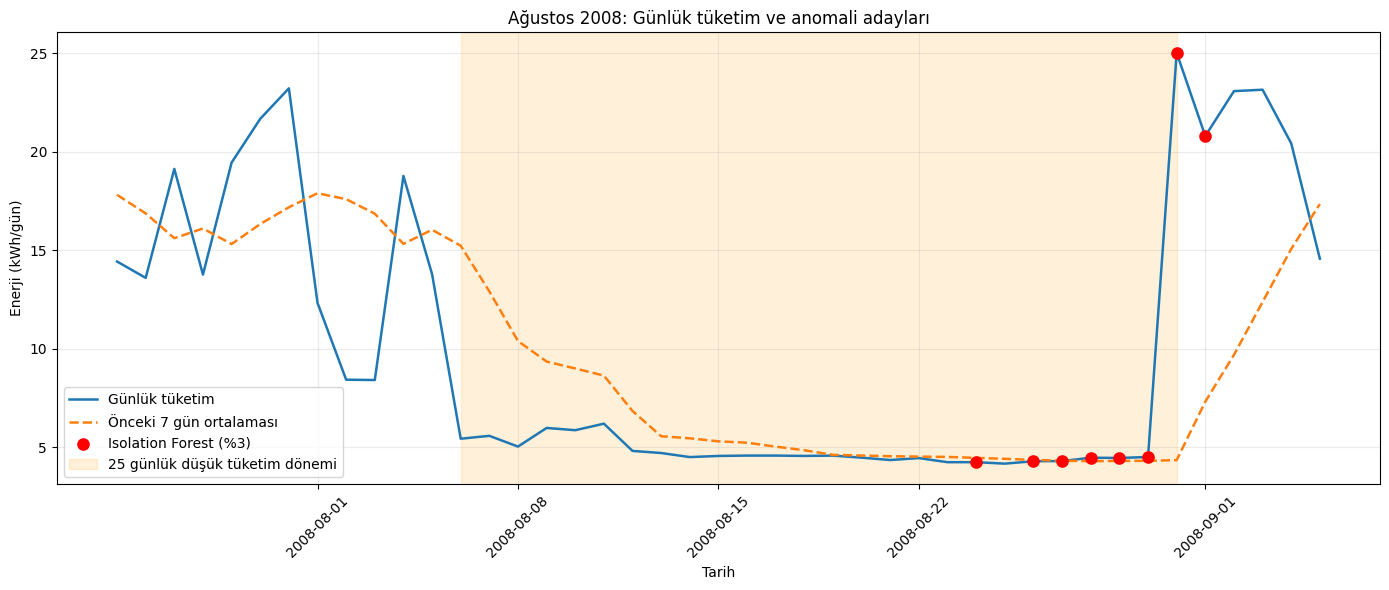

In [53]:
import matplotlib.pyplot as plt

# Ağustos 2008'deki düşük tüketim dönemi ve öncesi
plot_data = daily_features.loc[
    "2008-07-25":"2008-09-05"
].copy()

# Orijinal %3 modelinin tahminlerini ekle
plot_data = plot_data.join(
    results[["prediction"]],
    how="left"
)

flagged = plot_data[
    plot_data["prediction"] == -1
]

fig, ax = plt.subplots(figsize=(14, 6))

# Günlük tüketim
ax.plot(
    plot_data.index,
    plot_data["energy_kwh"],
    label="Günlük tüketim",
    linewidth=1.8
)

# Önceki 7 günün ortalaması
ax.plot(
    plot_data.index,
    plot_data["previous_7d_mean"],
    label="Önceki 7 gün ortalaması",
    linestyle="--",
    linewidth=1.8
)

# Modelin işaretlediği günler
ax.scatter(
    flagged.index,
    flagged["energy_kwh"],
    color="red",
    s=65,
    zorder=5,
    label="Isolation Forest (%3)"
)

# Uzun süreli düşük tüketim dönemi
ax.axvspan(
    pd.Timestamp("2008-08-06"),
    pd.Timestamp("2008-08-31"),
    color="orange",
    alpha=0.15,
    label="25 günlük düşük tüketim dönemi"
)

ax.set(
    title="Ağustos 2008: Günlük tüketim ve anomali adayları",
    xlabel="Tarih",
    ylabel="Enerji (kWh/gün)"
)

ax.legend()
ax.grid(alpha=0.25)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
from pathlib import Path

figure_dir = Path("../outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "august_2008_anomaly_analysis.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("Grafik kaydedildi:", figure_path)

Grafik kaydedildi: ../outputs/figures/august_2008_anomaly_analysis.png


## 16. Vaka analizi: Şubat 2008
25–28 Şubat 2008 döneminde tüketim düşmesine rağmen ana modelin bu günleri işaretlememesi, yöntemlerin farklı inceleme adayları ürettiğini gösterir.

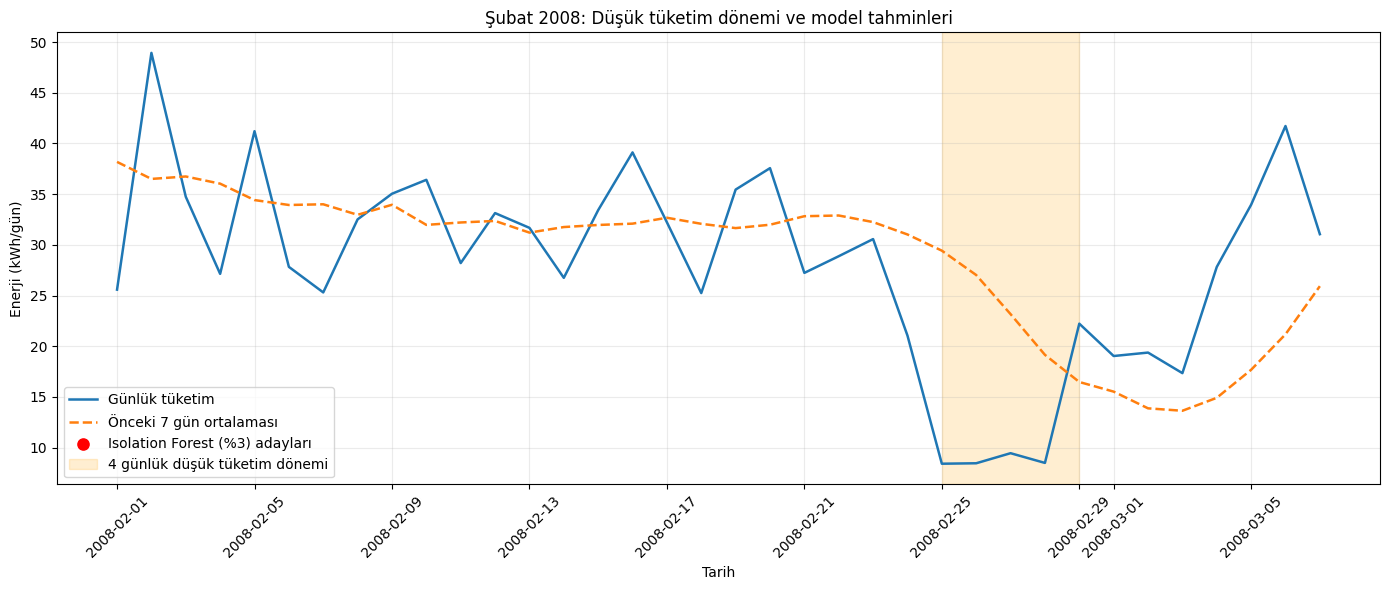

In [55]:
# Hücre 54: Şubat 2008 düşük tüketim dönemi

feb_plot = daily_features.loc[
    "2008-02-01":"2008-03-07"
].copy()

feb_plot = feb_plot.join(
    results[["prediction"]],
    how="left"
)

feb_flagged = feb_plot[
    feb_plot["prediction"] == -1
]

fig_feb, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    feb_plot.index,
    feb_plot["energy_kwh"],
    label="Günlük tüketim",
    linewidth=1.8
)

ax.plot(
    feb_plot.index,
    feb_plot["previous_7d_mean"],
    label="Önceki 7 gün ortalaması",
    linestyle="--",
    linewidth=1.8
)

ax.scatter(
    feb_flagged.index,
    feb_flagged["energy_kwh"],
    color="red",
    s=65,
    zorder=5,
    label="Isolation Forest (%3) adayları"
)

ax.axvspan(
    pd.Timestamp("2008-02-25"),
    pd.Timestamp("2008-02-29"),
    color="orange",
    alpha=0.18,
    label="4 günlük düşük tüketim dönemi"
)

ax.set(
    title="Şubat 2008: Düşük tüketim dönemi ve model tahminleri",
    xlabel="Tarih",
    ylabel="Enerji (kWh/gün)"
)

ax.legend()
ax.grid(alpha=0.25)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [56]:
figure_path_feb = figure_dir / "february_2008_low_consumption.png"

fig_feb.savefig(
    figure_path_feb,
    dpi=300,
    bbox_inches="tight"
)

print("Grafik kaydedildi:", figure_path_feb)

Grafik kaydedildi: ../outputs/figures/february_2008_low_consumption.png


## 17. Tüm dönem: %3 ve %5 Isolation Forest
Aynı altı özellik ve 200 ağaç kullanılarak yalnızca karar eşiği değiştirilmiştir. Mavi çizgi geçerli günlük tüketimi, kırmızı noktalar modelin işaretlediği günleri gösterir. Modelin değerlendiremediği günler “normal” kabul edilmez.

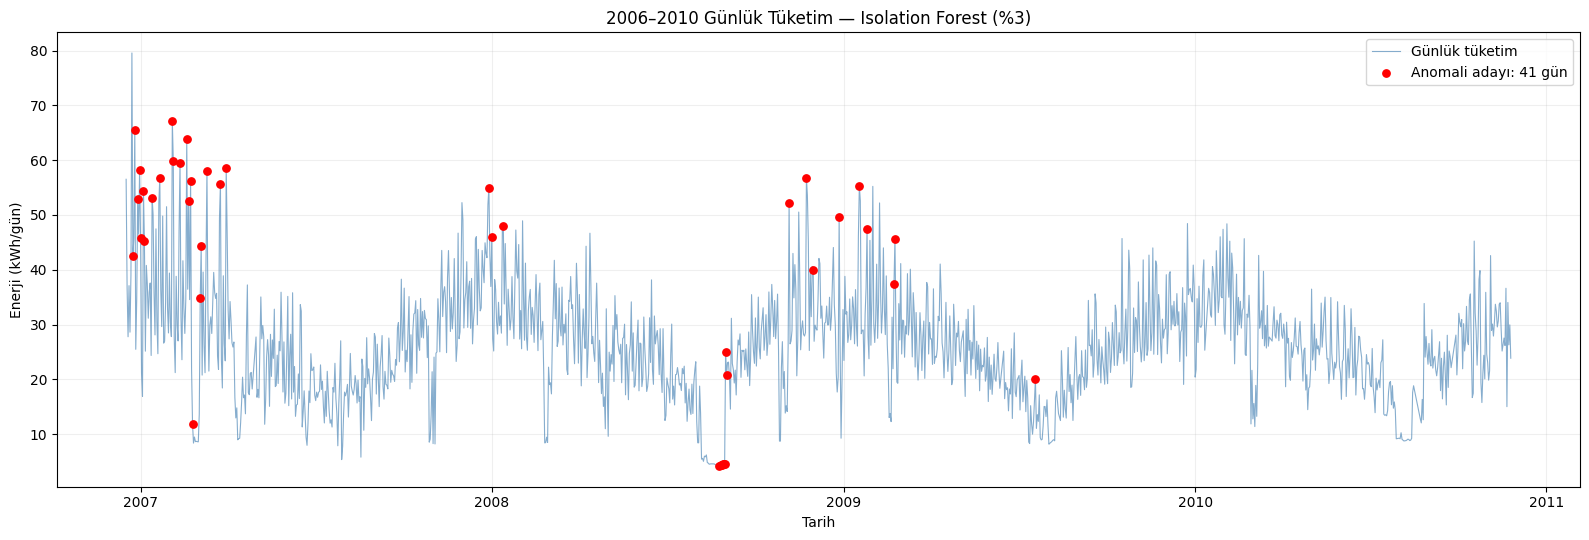

%3: 41 gün | Kaydedildi: ../outputs/figures/full_period_if_3pct.png


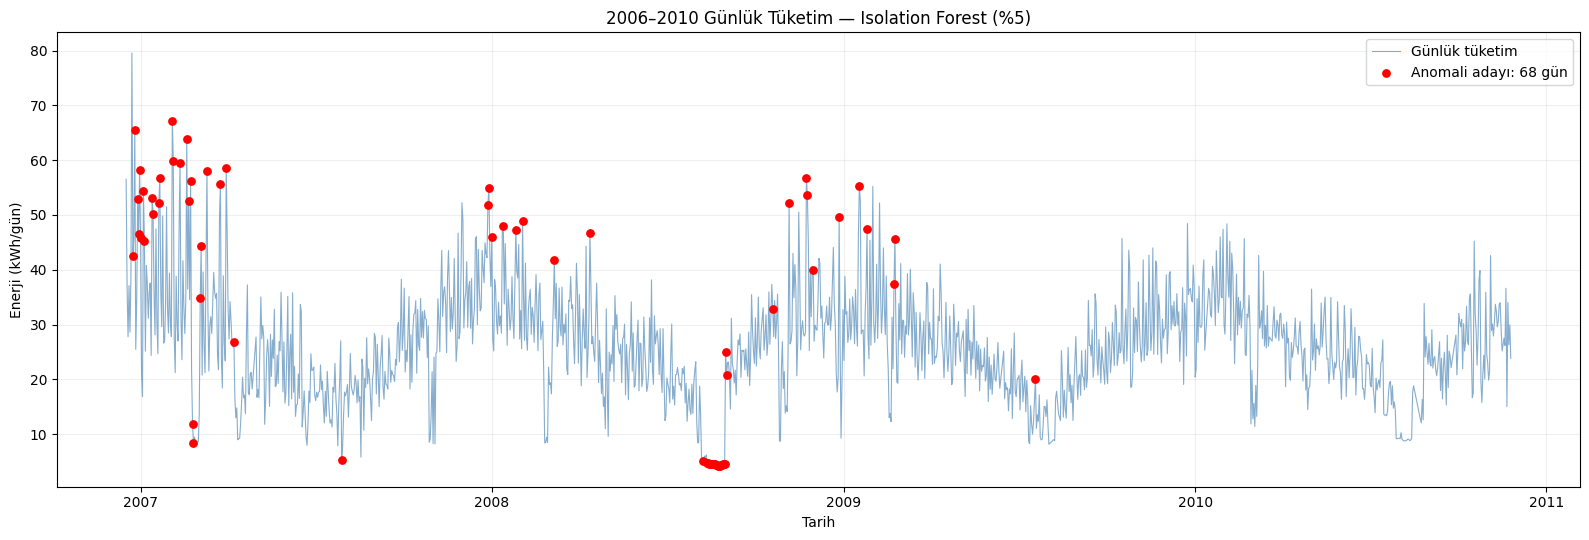

%5: 68 gün | Kaydedildi: ../outputs/figures/full_period_if_5pct.png


In [57]:
import matplotlib.dates as mdates

figure_dir = Path("../outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

for contamination in [0.03, 0.05]:
    predictions = sensitivity_predictions[contamination]
    flagged_dates = predictions.index[predictions == -1]
    flagged_energy = daily_features.loc[flagged_dates, "energy_kwh"]

    fig_full, ax = plt.subplots(figsize=(16, 5.5))
    ax.plot(daily_features.index, daily_features["energy_kwh"],
            color="steelblue", linewidth=0.8, alpha=0.65,
            label="Günlük tüketim")
    ax.scatter(flagged_dates, flagged_energy, color="red", s=28,
               zorder=5, label=f"Anomali adayı: {len(flagged_dates)} gün")
    ax.set(title=f"2006–2010 Günlük Tüketim — Isolation Forest (%{int(contamination*100)})",
           xlabel="Tarih", ylabel="Enerji (kWh/gün)")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
    fig_full.tight_layout()
    target = figure_dir / f"full_period_if_{int(contamination*100)}pct.png"
    fig_full.savefig(target, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"%{int(contamination*100)}: {len(flagged_dates)} gün | Kaydedildi: {target}")


## 18. Sonuçlar ve Sınırlılıklar

Bu projede, bir hanenin yaklaşık dört yıllık elektrik tüketim verilerini inceleyerek normalden farklı tüketim gösteren günleri belirlemeye çalıştım.

### Elde Edilen Sonuçlar

İlk olarak günlük tüketim verilerini hazırladım ve eksik ölçümleri kontrol ettim. Ardından Isolation Forest modelini kullanarak 1.345 gün arasından **41 günü anomali adayı** olarak belirledim. Modelin farklı ayarlarda nasıl sonuç verdiğini de karşılaştırdım.

Makine öğrenmesi modelinin yanında istatistiksel yöntemlerden yararlandım. Günlük tüketimleri genel olarak ve aylara göre karşılaştırdım. Ayrıca tüketimin birkaç gün boyunca normalden belirgin şekilde düşük olduğu **11 farklı dönem** tespit ettim.

Özellikle iki dönem dikkatimi çekti:

- **Şubat 2008:** Dört gün boyunca günlük ortalama tüketim 8,70 kWh olmasına rağmen model bu günleri anomali olarak işaretlemedi.
- **Ağustos 2008:** 25 gün boyunca günlük ortalama tüketim 4,76 kWh seviyesinde kaldı. Model, ana ayarında bu günlerin yalnızca altısını işaretledi.

Bu sonuçlar, tek bir yöntemin bütün tüketim değişikliklerini yakalayamadığını gösterdi. Farklı analiz yöntemlerini birlikte kullanarak daha fazla dikkat çekici dönemi inceleyebildim.

### Tüketim Değişimlerinin Olası Nedenleri

Bu çalışmada normalden farklı tüketim gösteren günleri belirledim ancak bu değişimlerin nedenlerini kesin olarak açıklayacak ek verilere sahip değildim.

İlgili tarihlerdeki hava durumu, evde yaşayan kişilerin çalışma saatleri, seyahatleri, elektrikli cihazların kullanımı veya planlı elektrik kesintileri gibi bilgiler olsaydı sonuçları daha ayrıntılı inceleyebilirdim. Sayaçların teknik kayıtları da olası ölçüm sorunlarını değerlendirmeye yardımcı olabilirdi.

### Çalışmanın Sınırlılıkları

Çalışmada yalnızca tek bir hanenin elektrik tüketim verilerini kullandım. Bu nedenle elde ettiğim sonuçların diğer hanelerde de aynı şekilde geçerli olacağını söyleyemem.

Veri setinde hangi günlerin gerçekten anormal olduğunu gösteren doğrulanmış bilgiler bulunmuyor. Bu yüzden modelin işaretlediği günlerin kesin olarak anormal olduğunu söylemek veya gerçek doğruluk oranını hesaplamak mümkün değil. Ayrıca modeli aynı veri üzerinde eğitip değerlendirdiğim için farklı verilerde nasıl sonuç vereceğini henüz test etmedim.

Günlük enerji hesaplarında eksik ölçümleri tamamlamadım. Bu nedenle bazı günlerin hesaplanan tüketimi gerçek tüketimden biraz düşük olabilir.

### Genel Değerlendirme

Bu projede elektrik tüketim verilerini temizleme, inceleme, günlük tüketim hesaplama ve farklı yöntemlerle olağan dışı tüketim dönemlerini belirleme aşamalarını gerçekleştirdim.

Düşük veya yüksek tüketim tek başına bir arıza, usulsüz kullanım ya da evin boş olduğu anlamına gelmez. Böyle bir sonuca ulaşmak için ek bilgilerle inceleme yapılması gerekir.
